## 1. Installation & Setup

In [ ]:
# Install Tinker SDK and dependencies
%pip install -q tinker transformers torch datasets numpy

In [ ]:
# 安装/更新 widgets 插件
%pip install -q -U ipywidgets jupyterlab_widgets

# 如果你是在本地 VS Code 或 Jupyter Lab 运行，建议安装完后重启一下内核 (Restart Kernel)

In [ ]:
# (Optional) Install the Tinker Cookbook for higher-level abstractions
!pip install -q git+https://github.com/thinking-machines-lab/tinker-cookbook.git

In [14]:
import os
from getpass import getpass

# Set your Tinker API key
if "TINKER_API_KEY" not in os.environ:
    os.environ["TINKER_API_KEY"] = getpass("Enter your Tinker API key: ")

# (Optional) HuggingFace token if the dataset is private/gated
if "HF_TOKEN" not in os.environ:
    os.environ["HF_TOKEN"] = getpass("Enter your HuggingFace token (or press Enter to skip): ")

In [1]:
import tinker
from tinker import types
import numpy as np
import json
import time

print("Core packages imported. Configure proxy below before creating the Tinker client.")


Core packages imported. Configure proxy below before creating the Tinker client.


## 2. Load and Audit the Four-Step Dataset

We use the locally generated four-step SFT dataset:

- `fourstep_qed_logp_mw_sft_train.jsonl`
- `fourstep_qed_logp_mw_sft_val.jsonl`

Each record already contains:
- `prompt` / `completion` for four-step SFT
- `messages` for direct chat-style supervision
- `source_input` / `source_output` so the later RL section can still use the original single-step task


In [2]:
# Configure proxy for Tinker / HuggingFace access when needed.

import os
import socket

proxy_host = "172.18.48.1"
proxy_port = 7897
proxy_url = f"http://{proxy_host}:{proxy_port}"


def test_port(ip, port):
    with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
        s.settimeout(2)
        return s.connect_ex((ip, port)) == 0


if test_port(proxy_host, proxy_port):
    print(f"Connected proxy: {proxy_url}")
    os.environ["http_proxy"] = proxy_url
    os.environ["https_proxy"] = proxy_url
else:
    print(
        f"Proxy {proxy_url} is not reachable. Continue only if your environment can reach Tinker directly."
    )


Connected proxy: http://172.18.48.1:7897


In [4]:
from pathlib import Path
from datasets import load_dataset
from tinker_cookbook import renderers, tokenizer_utils

service_client = tinker.ServiceClient()
capabilities = service_client.get_server_capabilities()
print("Connected to Tinker. Qwen3 models:")
for model in capabilities.supported_models:
    if "Qwen3" in model.model_name:
        print(f"  - {model.model_name}")


Connected to Tinker. Qwen3 models:
  - Qwen/Qwen3-235B-A22B-Instruct-2507
  - Qwen/Qwen3-30B-A3B
  - Qwen/Qwen3-30B-A3B-Base
  - Qwen/Qwen3-30B-A3B-Instruct-2507
  - Qwen/Qwen3-32B
  - Qwen/Qwen3-4B-Instruct-2507
  - Qwen/Qwen3-8B
  - Qwen/Qwen3-8B-Base
  - Qwen/Qwen3-VL-235B-A22B-Instruct
  - Qwen/Qwen3-VL-30B-A3B-Instruct
  - Qwen/Qwen3.5-27B
  - Qwen/Qwen3.5-35B-A3B
  - Qwen/Qwen3.5-397B-A17B
  - Qwen/Qwen3.5-397B-A17B:peft:262144
  - Qwen/Qwen3.5-4B
  - Qwen/Qwen3.6-27B
  - Qwen/Qwen3.6-35B-A3B


In [5]:
import re
from collections import Counter

FOURSTEP_DATA_FILES = {
    "train": str(Path("datasets_v2/phase1_4000_intent/fourstep_qed_logp_mw_sft_train_v2_intent_4000.jsonl").resolve()),
    "validation": str(Path("datasets_v2/phase1_4000_intent/fourstep_qed_logp_mw_sft_val_v2_intent_200.jsonl").resolve()),
}

for split_name, file_path in FOURSTEP_DATA_FILES.items():
    if not Path(file_path).exists():
        raise FileNotFoundError(f"Missing {split_name} file: {file_path}")

fourstep_dataset = load_dataset("json", data_files=FOURSTEP_DATA_FILES)
sft_train_raw = fourstep_dataset["train"]
sft_val_raw = fourstep_dataset["validation"]
rl_raw_data = sft_train_raw

SFT_PROMPT_COL = "prompt"
SFT_ANSWER_COL = "completion"
SFT_MESSAGES_COL = "messages"
RL_PROMPT_COL = "source_input"
RL_ANSWER_COL = "source_output"

print("Loaded source SFT dataset (four-step records; PLAN+EDIT view will be derived dynamically)")
print(f"  train: {len(sft_train_raw)}")
print(f"  validation: {len(sft_val_raw)}")
print(f"  columns: {sft_train_raw.column_names}")


Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Loaded source SFT dataset (four-step records; PLAN+EDIT view will be derived dynamically)
  train: 4000
  validation: 200
  columns: ['prompt', 'completion', 'messages', 'source_index', 'source_input', 'source_output', 'input_smiles', 'target_smiles', 'action_type', 'fragments', 'targets', 'input_props', 'output_props', 'actual_prop_deltas', 'target_met', 'dataset_version', 'plan_schema', 'plan_direction_labels']


In [6]:
def audit_fourstep_split(split_name, split_data):
    summary = Counter()
    plan_line_counts = Counter()

    for example in split_data:
        completion_text = str(example[SFT_ANSWER_COL])
        summary["xml_tags"] += int(
            all(tag in completion_text for tag in ["<ANALYSE>", "<PLAN>", "<EDIT>", "<VERIFY>"])
        )
        summary["bracket_tags"] += int(
            all(tag in completion_text for tag in ["[ANALYZE]", "[PLAN]", "[EDIT]", "[VERIFY]"])
        )
        summary["templated_plan"] += int(
            "This source edit is kept because the resulting molecule moves the measured properties toward the requested directions"
            in completion_text
        )
        plan_match = re.search(r"<PLAN>\n(.*?)\n</PLAN>", completion_text, re.DOTALL)
        if plan_match:
            plan_lines = [line for line in plan_match.group(1).splitlines() if line.strip()]
            plan_line_counts[len(plan_lines)] += 1

    total = len(split_data)
    print(f"[{split_name}] records={total}")
    print(f"  xml-tag format: {summary['xml_tags']}/{total}")
    print(f"  bracket-tag format: {summary['bracket_tags']}/{total}")
    print(f"  templated PLAN phrasing: {summary['templated_plan']}/{total}")
    print(f"  PLAN line counts: {dict(plan_line_counts)}")


audit_fourstep_split("train", sft_train_raw)
audit_fourstep_split("validation", sft_val_raw)

# RL later in the notebook still expects single-step prompt/answer fields.
PROMPT_COL = RL_PROMPT_COL
ANSWER_COL = RL_ANSWER_COL
raw_data = rl_raw_data

print(f"RL raw_data view prepared from train split: {len(raw_data)} examples")
print(f"RL prompt column: {PROMPT_COL}")
print(f"RL answer column: {ANSWER_COL}")


[train] records=4000
  xml-tag format: 4000/4000
  bracket-tag format: 0/4000
  templated PLAN phrasing: 0/4000
  PLAN line counts: {3: 4000}
[validation] records=200
  xml-tag format: 200/200
  bracket-tag format: 0/200
  templated PLAN phrasing: 0/200
  PLAN line counts: {3: 200}
RL raw_data view prepared from train split: 4000 examples
RL prompt column: source_input
RL answer column: source_output


## 3. Configure the Model and Renderer

We'll use **Qwen3-8B** (a good balance of cost and capability). For larger-scale experiments, you can switch to `Qwen/Qwen3-30B-A3B` (MoE, very cost-effective) or `Qwen/Qwen3-32B` (dense).

Tinker uses a **Renderer** to convert chat messages into token sequences with proper special tokens and loss weights.

In [7]:
# Choose your base model
# Options: "Qwen/Qwen3-8B", "Qwen/Qwen3-30B-A3B", "Qwen/Qwen3-32B", etc.
BASE_MODEL = "Qwen/Qwen3-8B"

# LoRA rank: higher = more capacity but costs more. 32 is a good default.
LORA_RANK = 32

print(f"Base model: {BASE_MODEL}")
print(f"LoRA rank: {LORA_RANK}")

Base model: Qwen/Qwen3-8B
LoRA rank: 32


In [8]:
# Set up the renderer for Qwen3 chat format
# The renderer handles special tokens (<|im_start|>, <|im_end|>, etc.)
# and produces proper loss masks for training.

from tinker_cookbook import renderers, tokenizer_utils

tokenizer = tokenizer_utils.get_tokenizer(BASE_MODEL)
# RENDERER_NAME = "qwen3_disable_thinking"
RENDERER_NAME = "qwen3"

renderer = renderers.get_renderer(RENDERER_NAME, tokenizer)

print(f"Using renderer: {RENDERER_NAME}")
print(f"Tokenizer vocab size: {tokenizer.vocab_size}")
print(f"Stop sequences: {renderer.get_stop_sequences()}")

Using renderer: qwen3
Tokenizer vocab size: 151643
Stop sequences: [151645]


## 4. Data Preparation Helpers

We need functions to convert our dataset into the format Tinker expects:
- **For SFT:** `types.Datum` with `model_input` and `loss_fn_inputs` (weights and target_tokens)
- **For GRPO:** Chat messages that can be rendered into prompts for sampling

In [28]:
DEFAULT_SFT_SYSTEM_PROMPT = """You are a chemistry assistant for multi-turn molecule optimization.
The user may provide a program-generated <ANALYSE> block as trusted context.
At each turn, output EXACTLY the following two labeled blocks in order:

<PLAN>
Before writing the edit, use the trusted ANALYSE context to decide the next fragment-level strategy. Do not explain a pre-given edit; reason about the property gaps first, then choose the operation you will write in EDIT.
</PLAN>

<EDIT>
Replace/Add/Remove ... to form <SMILES>...</SMILES>.
</EDIT>

Do not output ANALYSE or VERIFY blocks."""


def _extract_xml_block(text: str | None, tag: str) -> str:
    if not text:
        return ""
    m = re.search(rf"<{tag}>\s*(.*?)\s*</{tag}>", str(text), re.DOTALL)
    return m.group(1).strip() if m else ""


def build_two_step_user_prompt(example, include_analysis: bool = True) -> str:
    base_prompt = str(example.get(RL_PROMPT_COL) or example.get(SFT_PROMPT_COL) or "")
    analyse_block = _extract_xml_block(example.get("completion"), "ANALYSE")
    if not analyse_block:
        analyse_block = _extract_xml_block(example.get("completion"), "ANALYZE")
    if (not include_analysis) or (not analyse_block):
        return base_prompt
    return (
        base_prompt
        + "\n\nProgram-generated analysis context (trusted, do not repeat verbatim):\n"
        + "<ANALYSE>\n"
        + analyse_block
        + "\n</ANALYSE>"
    )


def build_two_step_assistant_completion(example) -> str:
    full_completion = str(example.get("completion") or example.get(SFT_ANSWER_COL) or "")
    plan_block = _extract_xml_block(full_completion, "PLAN")
    edit_block = _extract_xml_block(full_completion, "EDIT")
    if plan_block and edit_block:
        return f"<PLAN>\n{plan_block}\n</PLAN>\n\n<EDIT>\n{edit_block}\n</EDIT>"
    source_output = str(example.get("source_output") or example.get(ANSWER_COL) or "")
    return f"<PLAN>\nProvide a chemically grounded rationale for the edit.\n</PLAN>\n\n<EDIT>\n{source_output}\n</EDIT>"


print("SFT system prompt realigned to PLAN+EDIT supervision view.")


def make_sft_messages(example, system_prompt=DEFAULT_SFT_SYSTEM_PROMPT):
    return [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": build_two_step_user_prompt(example)},
        {"role": "assistant", "content": build_two_step_assistant_completion(example)},
    ]


def make_sft_prompt_messages(example, system_prompt=DEFAULT_SFT_SYSTEM_PROMPT):
    return [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": build_two_step_user_prompt(example)},
    ]


SYSTEM_PROMPT = DEFAULT_SFT_SYSTEM_PROMPT


def make_messages(example):
    return [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": build_two_step_user_prompt(example)},
        {"role": "assistant", "content": build_two_step_assistant_completion(example)},
    ]


def make_prompt_messages(example, system_prompt=SYSTEM_PROMPT):
    return [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": build_two_step_user_prompt(example)},
    ]
# print(SYSTEM_PROMPT)

SFT system prompt realigned to PLAN+EDIT supervision view.


## 5. Stage 1: Supervised Fine-Tuning (SFT)

SFT teaches the model the basic format and chemistry knowledge. We use the `cross_entropy` loss function, which trains the model to predict the next token for the assistant's response.

**Tinker's training loop:**
1. Prepare a batch of `Datum` objects
2. Call `forward_backward()` to compute gradients
3. Call `optim_step()` to update the LoRA weights
4. Repeat

In [11]:
# ========================
# SFT Hyperparameters
# ========================
SFT_LEARNING_RATE = 1e-4
SFT_BATCH_SIZE = 4
SFT_NUM_STEPS = 500
SFT_EVAL_EVERY = 10
SFT_SEED = 42
SFT_MAX_TRAIN_EXAMPLES = None  # Set an int for quick debugging.
SFT_MAX_VAL_EXAMPLES = None
SFT_INIT_CHECKPOINT = None

print(
    f"SFT config: lr={SFT_LEARNING_RATE}, batch={SFT_BATCH_SIZE}, "
    f"steps={SFT_NUM_STEPS}, eval_every={SFT_EVAL_EVERY}"
)


SFT config: lr=0.0001, batch=4, steps=500, eval_every=10


In [12]:
def _slice_split(split, max_examples=None):
    if max_examples is None:
        return split
    return split.select(range(min(max_examples, len(split))))


sft_train_examples = _slice_split(sft_train_raw, SFT_MAX_TRAIN_EXAMPLES)
sft_val_examples = _slice_split(sft_val_raw, SFT_MAX_VAL_EXAMPLES)


# Adapted from multiStepRL_initial.ipynb: convert rendered chat messages into
# Tinker supervised Datum objects with shifted CE targets.
def prepare_sft_datum(example):
    messages = make_sft_messages(example)
    model_input, weights = renderer.build_supervised_example(messages)

    input_tokens = model_input.to_ints()
    weights_list = weights.tolist() if hasattr(weights, "tolist") else list(weights)

    target_tokens = input_tokens[1:] + [input_tokens[-1]]
    weights_shifted = weights_list[1:] + [0]

    return types.Datum(
        model_input=types.ModelInput.from_ints(tokens=input_tokens[:-1]),
        loss_fn_inputs={
            "weights": weights_shifted[:-1],
            "target_tokens": target_tokens[:-1],
        },
    )


print(f"SFT train examples: {len(sft_train_examples)}")
print(f"SFT val examples: {len(sft_val_examples)}")


SFT train examples: 4000
SFT val examples: 200


In [13]:
def build_sft_split(split_name, split_data):
    datums = []
    failures = []
    for idx, example in enumerate(split_data):
        try:
            datums.append(prepare_sft_datum(example))
        except Exception as exc:
            failures.append((idx, str(exc)))
            if len(failures) <= 3:
                print(f"[{split_name}] skip example {idx}: {exc}")

    print(f"[{split_name}] prepared {len(datums)} datums, skipped {len(failures)}")
    return datums, failures


sft_training_client = service_client.create_lora_training_client(
    base_model=BASE_MODEL,
    rank=LORA_RANK,
)
if SFT_INIT_CHECKPOINT:
    sft_training_client.load_state_with_optimizer(SFT_INIT_CHECKPOINT)
    print(f"Loaded existing SFT state: {SFT_INIT_CHECKPOINT}")

sft_train, sft_train_failures = build_sft_split("train", sft_train_examples)
sft_val, sft_val_failures = build_sft_split("validation", sft_val_examples)

if not sft_train:
    raise ValueError("No SFT training datums were prepared.")


[train] prepared 4000 datums, skipped 0
[validation] prepared 200 datums, skipped 0


In [14]:
def _tensor_like_to_array(value, dtype=np.float64):
    if hasattr(value, "to_numpy"):
        return np.asarray(value.to_numpy(), dtype=dtype)
    if hasattr(value, "tolist"):
        return np.asarray(value.tolist(), dtype=dtype)
    return np.asarray(list(value), dtype=dtype)


def _cross_entropy_loss(batch, fwdbwd_result):
    logprobs = np.concatenate(
        [
            _tensor_like_to_array(out["logprobs"], dtype=np.float64)
            for out in fwdbwd_result.loss_fn_outputs
        ]
    )
    weights = np.concatenate(
        [
            _tensor_like_to_array(d.loss_fn_inputs["weights"], dtype=np.float64)
            for d in batch
        ]
    )
    return float(-np.dot(logprobs, weights) / max(weights.sum(), 1.0))


sft_metrics = []
rng = np.random.default_rng(SFT_SEED)
train_batch_size = min(SFT_BATCH_SIZE, len(sft_train))
val_batch_size = min(SFT_BATCH_SIZE, len(sft_val)) if sft_val else 0

print("Starting SFT training...")
print(f"{'Step':>5} | {'Train Loss':>10} | {'Val Loss':>10} | {'Time (s)':>8}")
print("-" * 50)

for step in range(SFT_NUM_STEPS):
    t0 = time.time()

    batch_indices = rng.choice(len(sft_train), size=train_batch_size, replace=False)
    batch = [sft_train[i] for i in batch_indices]

    fwdbwd_future = sft_training_client.forward_backward(batch, loss_fn="cross_entropy")
    optim_future = sft_training_client.optim_step(
        types.AdamParams(learning_rate=SFT_LEARNING_RATE)
    )

    fwdbwd_result = fwdbwd_future.result()
    optim_future.result()
    train_loss = _cross_entropy_loss(batch, fwdbwd_result)

    elapsed = time.time() - t0
    metrics_entry = {"step": step, "train_loss": train_loss, "time": elapsed}

    if step % SFT_EVAL_EVERY == 0 and sft_val:
        val_batch = [sft_val[i] for i in range(val_batch_size)]
        val_result = sft_training_client.forward_backward(val_batch, loss_fn="cross_entropy").result()
        val_loss = _cross_entropy_loss(val_batch, val_result)
        metrics_entry["val_loss"] = val_loss
        print(f"{step:>5} | {train_loss:>10.4f} | {val_loss:>10.4f} | {elapsed:>8.1f}")
    else:
        print(f"{step:>5} | {train_loss:>10.4f} | {'-':>10} | {elapsed:>8.1f}")

    sft_metrics.append(metrics_entry)

print("SFT training complete.")


Starting SFT training...
 Step | Train Loss |   Val Loss | Time (s)
--------------------------------------------------
    0 |     2.4496 |     2.2894 |    208.2
    1 |     1.9997 |          - |      2.3
    2 |     1.8225 |          - |      2.5
    3 |     1.7415 |          - |      2.3
    4 |     1.7015 |          - |      2.4
    5 |     1.4877 |          - |      2.3
    6 |     1.4636 |          - |      2.3
    7 |     1.2685 |          - |      2.8
    8 |     1.3650 |          - |      2.3
    9 |     1.2313 |          - |      2.3
   10 |     1.2017 |     1.2218 |      2.3
   11 |     0.9896 |          - |      3.0
   12 |     1.0716 |          - |      2.3
   13 |     0.9876 |          - |      2.3
   14 |     0.9886 |          - |      2.3
   15 |     0.9836 |          - |      2.3
   16 |     0.7308 |          - |      2.3
   17 |     0.8131 |          - |      2.3
   18 |     0.7136 |          - |      2.8
   19 |     0.8684 |          - |      2.3
   20 |     0.7373 | 

In [15]:
base_model_tag = BASE_MODEL.split("/")[-1].replace(".", "-")
SFT_CHECKPOINT_NAME = f"Subprocess-sft500-fourstep-xml.{base_model_tag}"
SFT_SAMPLER_NAME = f"{SFT_CHECKPOINT_NAME}.sampler"

sft_save_result = sft_training_client.save_state(name=SFT_CHECKPOINT_NAME).result()
sft_checkpoint_path = sft_save_result.path
print(f"SFT checkpoint saved at: {sft_checkpoint_path}")

sft_sampling_client = sft_training_client.save_weights_and_get_sampling_client(
    name=SFT_SAMPLER_NAME
)
print("SFT sampling client ready")


SFT checkpoint saved at: tinker://3b6c008f-c911-5983-8ca8-4b92099cd6f0:train:0/weights/Subprocess-sft500-fourstep-xml.Qwen3-8B
SFT sampling client ready


In [16]:
test_example = sft_val_raw[0] if len(sft_val_raw) > 0 else sft_train_raw[0]
test_prompt_msgs = make_sft_prompt_messages(test_example)
prompt_input = renderer.build_generation_prompt(test_prompt_msgs)
stop_seqs = renderer.get_stop_sequences()

sample_result = sft_sampling_client.sample(
    prompt=prompt_input,
    sampling_params=types.SamplingParams(
        max_tokens=512,
        temperature=0.3,
        stop=stop_seqs,
    ),
    num_samples=1,
).result()

response_text = tokenizer.decode(
    sample_result.sequences[0].tokens,
    skip_special_tokens=True,
).replace("<|im_end|>", "").strip()

print("=" * 60)
print("PROMPT:")
print(test_example[SFT_PROMPT_COL][:800])
print("=" * 60)
print("MODEL RESPONSE (SFT):")
print(response_text)
print("=" * 60)
print("GROUND TRUTH:")
print(test_example[SFT_ANSWER_COL])


PROMPT:
Given the intermediate molecule SMILES <SMILES>O=C(NCCc1nnc2n1CCC2)C1CCN(C(=O)c2cccs2)CC1</SMILES>, which is composed of fragments ['C()=O', 'N', 'CC', 'c1nnc2n1CCC2', 'N1CCC()CC1', 'C()=O', 'c1cccs1']. Propose a single replace, add or remove step on fragment level that makes the new molecule's QED <QED>0.023</QED> higher, LogP <LogP>0.574</LogP> higher, and Molecular Weight <MW>22.998</MW> lower.
MODEL RESPONSE (SFT):
<PLAN>
Reasoning: Replacing the nitrile-containing fragment with a cyclic ether may reduce polarity and increase lipophilicity while decreasing molecular weight through structural simplification. This change could improve QED by enhancing drug-like properties and increase LogP by reducing hydrogen bonding capacity.
Proposed edit: Replace starting fragment 4, the aromatic hydrogen bonding heteroatom rich motif, with a ring containing hydrogen bonding heteroatom containing replacement motif to target higher QED, higher LogP, and lower MW.
Expected effect: QED will 

## 6. Plot SFT Training Curves

---

## 7. Stage 2: Reinforcement Learning

Now we switch to **GRPO-style RL training** to improve the model's accuracy using a reward signal.

**How GRPO works with Tinker:**
1. For each prompt, **sample G completions** from the current model
2. **Score** each completion with a reward function
3. Compute **group-normalized advantages** (subtract mean, divide by std within each group)
4. Use the `ppo` (or `importance_sampling`) loss to update the policy

Tinker's built-in `ppo` loss handles the clipped surrogate objective. The GRPO-specific part (group normalization of advantages) is done on the client side.

---

## 关于qed logp mw的rewardFunc

In [41]:
import re
from rdkit import Chem
from rdkit import DataStructs
from rdkit.Chem import QED
from rdkit.Chem import Descriptors
from rdkit.Chem import Crippen
from rdkit.Chem import rdFingerprintGenerator
from rdkit import RDLogger
RDLogger.DisableLog("rdApp.*")
from typing import Dict, List, Tuple
from collections import defaultdict, deque


def _canonical_smiles(smiles_text: str) -> str | None:
    """Return canonical SMILES, or None if parsing fails."""
    if not smiles_text:
        return None
    mol = Chem.MolFromSmiles(smiles_text)
    if mol is None:
        return None
    return Chem.MolToSmiles(mol)


def strict_format_reward(completions: List[str], **kwargs) -> List[float]:
    """
    +1.0 if the completion matches:
      'Replace ... with ... to form <SMILES>...</SMILES>.'   OR
      'Add ... to form <SMILES>...</SMILES>.'                OR
      'Remove ... to form <SMILES>...</SMILES>.'
    else -4.0
    """
    pat = re.compile(
        r"^(Replace|Add|Remove)\s+(.+?)(?:\s+with\s+(.+?))?\s+to\s+form\s+<SMILES>(.+)</SMILES>\.$",
        re.DOTALL,
    )
    rewards = []
    for text in completions:
        edit_text = _extract_edit_text_for_reward(text.strip())
        m = pat.fullmatch(edit_text)
        rewards.append(1.0 if m else -4.0)
    return rewards


REPETITION_WINDOW_ITERATIONS = 2
REPETITION_PENALTY_STEP = 0.1
REPETITION_PENALTY_FLOOR = -0.4
_repetition_iteration_window = deque()
_repetition_history_counts = defaultdict(int)


def _extract_edit_text_for_reward(text: str) -> str:
    edit_block = _extract_xml_block(text, "EDIT")
    return edit_block.strip() if edit_block else text.strip()


def _has_plan_edit_blocks(text: str) -> bool:
    return bool(_extract_xml_block(text, "PLAN") and _extract_xml_block(text, "EDIT"))


def reset_repetition_window() -> None:
    global _repetition_iteration_window, _repetition_history_counts
    _repetition_iteration_window = deque()
    _repetition_history_counts = defaultdict(int)


def configure_repetition_window(
    window_size_iterations: int = 2,
    penalty_step: float = 0.1,
    penalty_floor: float = -0.4,
) -> dict[str, float]:
    if window_size_iterations < 1:
        raise ValueError("window_size_iterations must be >= 1")
    if penalty_step < 0.0:
        raise ValueError("penalty_step must be >= 0")
    if penalty_floor > 0.0:
        raise ValueError("penalty_floor must be <= 0")

    globals()["REPETITION_WINDOW_ITERATIONS"] = int(window_size_iterations)
    globals()["REPETITION_PENALTY_STEP"] = float(penalty_step)
    globals()["REPETITION_PENALTY_FLOOR"] = float(penalty_floor)
    reset_repetition_window()
    return {
        "window_size_iterations": int(REPETITION_WINDOW_ITERATIONS),
        "penalty_step": float(REPETITION_PENALTY_STEP),
        "penalty_floor": float(REPETITION_PENALTY_FLOOR),
    }


def _current_repetition_history_counts() -> dict[str, int]:
    return dict(_repetition_history_counts)


def _extract_final_canonical_smiles_for_repetition(text: str) -> str | None:
    edit_text = _extract_edit_text_for_reward(text or "")
    m = re.search(r"<SMILES>(.*?)</SMILES>", edit_text)
    if not m:
        return None
    return _canonical_smiles(m.group(1).strip())


def collect_repetition_smiles(completions: List[str], **kwargs) -> List[str]:
    collected = []
    for text in completions:
        can = _extract_final_canonical_smiles_for_repetition(text)
        if can:
            collected.append(can)
    return collected


def update_repetition_history(smiles_list: List[str]) -> dict[str, int]:
    global _repetition_iteration_window, _repetition_history_counts

    bucket = [smi for smi in smiles_list if smi]
    _repetition_iteration_window.append(bucket)
    while len(_repetition_iteration_window) > REPETITION_WINDOW_ITERATIONS:
        _repetition_iteration_window.popleft()

    new_counts = defaultdict(int)
    for hist_bucket in _repetition_iteration_window:
        for smi in hist_bucket:
            new_counts[smi] += 1
    _repetition_history_counts = new_counts
    return dict(_repetition_history_counts)


def repetition_penalty_reward(
    completions: List[str],
    history_counts: Dict[str, int] | None = None,
    **kwargs,
) -> List[float]:
    """Penalize short-term duplicate final canonical SMILES only."""
    counts = history_counts if history_counts is not None else _current_repetition_history_counts()
    rewards = []
    for text in completions:
        can = _extract_final_canonical_smiles_for_repetition(text)
        if not can:
            rewards.append(0.0)
            continue

        count = int(counts.get(can, 0))
        penalty = max(-REPETITION_PENALTY_STEP * count, REPETITION_PENALTY_FLOOR)
        rewards.append(float(penalty))
    return rewards


configure_repetition_window()


def multi_property_reward(completions: List[str], **kwargs) -> List[float]:
    """
    Reward in [-2, 1], derived from direction-aware normalized error.

    We cap total error before mapping to reward to avoid saturation near -4,
    which keeps property signal informative for RL updates.
    """
    prompts: List[str] = kwargs["prompts"]
    out = []

    # Cap controls floor: reward = 1 - clip(total_err, 0, cap) -> [1-cap, 1]
    err_cap = 3.0

    for comp, prompt in zip(completions, prompts):
        comp = _extract_edit_text_for_reward(comp)
        in_m = re.search(r"<SMILES>(.*?)</SMILES>", prompt)
        out_m = re.search(r"<SMILES>(.*?)</SMILES>", comp)
        qed_m = re.search(r"<QED>(-?\d+\.\d+)</QED>\s*(higher|lower)", prompt)
        logp_m = re.search(r"<LogP>(-?\d+\.\d+)</LogP>\s*(higher|lower)", prompt)
        mw_m = re.search(r"<MW>(-?\d+\.\d+)</MW>\s*(higher|lower)", prompt)

        if not (in_m and out_m and qed_m and logp_m and mw_m):
            out.append(-4.0)
            continue

        s_in, s_out = in_m.group(1), out_m.group(1)
        m_in, m_out = Chem.MolFromSmiles(s_in), Chem.MolFromSmiles(s_out)
        if not (m_in and m_out):
            out.append(-4.0)
            continue

        qed_in = QED.qed(m_in)
        logp_in = Crippen.MolLogP(m_in)
        mw_in = Descriptors.ExactMolWt(m_in)

        qed_out = QED.qed(m_out)
        logp_out = Crippen.MolLogP(m_out)
        mw_out = Descriptors.ExactMolWt(m_out)

        def _parse(m, base):
            delta = float(m.group(1))
            direction = 1 if m.group(2) == "higher" else -1
            return base + direction * delta, direction

        qed_t, d_qed = _parse(qed_m, qed_in)
        logp_t, d_logp = _parse(logp_m, logp_in)
        mw_t, d_mw = _parse(mw_m, mw_in)

        qed_t = max(0.01, min(0.99, qed_t))

        qed_err = abs(qed_out - qed_t) / 0.5
        logp_err = abs(logp_out - logp_t) / 3.0
        mw_err = abs(mw_out - mw_t) / 50.0

        dir_pen_qed = 4 if (qed_out - qed_in) * d_qed < 0 else 1
        dir_pen_logp = 4 if (logp_out - logp_in) * d_logp < 0 else 1
        dir_pen_mw = 4 if (mw_out - mw_in) * d_mw < 0 else 1

        total_err = (
            qed_err * dir_pen_qed
            + logp_err * dir_pen_logp
            + mw_err * dir_pen_mw
        )

        bounded_err = min(max(total_err, 0.0), err_cap)
        reward = 1.0 - bounded_err
        out.append(reward)
    return out


In [42]:
"""
Reward utilities for non-four-step training.

This version removes ANALYZE/PLAN/EDIT/VERIFY step parsing and scores
the model directly from completion text, prompt, and ground truth.
"""

RDLogger.DisableLog("rdApp.*")


def extract_smiles(text: str | None) -> str | None:
    """Extract SMILES inside <SMILES>...</SMILES>."""
    if not text:
        return None
    m = re.search(r"<SMILES>(.*?)</SMILES>", text)
    return m.group(1).strip() if m else None


def _normalize_completion_text(text: str) -> str:
    """Drop think blocks and surrounding spaces."""
    if not text:
        return ""
    clean = re.sub(r"<think>.*?</think>", "", text, flags=re.DOTALL)
    return clean.replace("<|im_end|>", "").strip()


def _extract_edit_text(text: str) -> str:
    edit_block = _extract_xml_block(text, "EDIT")
    return edit_block.strip() if edit_block else text.strip()

_MORGAN_GEN = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
def compute_similarity_reward(mol_pred, mol_target) -> float:
    """Tanimoto similarity on Morgan fingerprints."""
    if mol_pred is None or mol_target is None:
        return 0.0
    fp_pred = _MORGAN_GEN.GetFingerprint(mol_pred)
    fp_target = _MORGAN_GEN.GetFingerprint(mol_target)
    return float(DataStructs.TanimotoSimilarity(fp_pred, fp_target))


SOFT_FORMAT_FLOOR = -4.0
SOFT_PROPERTY_FLOOR = -2.5
TOTAL_REWARD_FLOOR = -2.0

# Reward decomposition for per-iteration diagnostics.
BASE_REWARD_WEIGHTS = {
    "property": 0.70,
    "format": 0.20,
    "similarity": 0.20,
    "repetition": 0.05,
}
DEFAULT_BASE_REWARD_WEIGHTS = dict(BASE_REWARD_WEIGHTS)


def set_base_reward_weights(weights: dict[str, float] | None = None) -> dict[str, float]:
    source = DEFAULT_BASE_REWARD_WEIGHTS if weights is None else weights
    BASE_REWARD_WEIGHTS.clear()
    BASE_REWARD_WEIGHTS.update({key: float(value) for key, value in source.items()})
    return dict(BASE_REWARD_WEIGHTS)


def resolve_reward_weights(use_repetition_reward: bool = False) -> dict[str, float]:
    weights = dict(BASE_REWARD_WEIGHTS)
    if not use_repetition_reward:
        weights["repetition"] = 0.0
    return weights


def compute_reward_components(
    completion_text: str,
    prompt_text: str,
    ground_truth: str,
    reward_weights: dict[str, float] | None = None,
    repetition_history_counts: dict[str, int] | None = None,
) -> dict:
    """
    Return decomposed reward terms for diagnostics and training.

    Keys:
      strict, property, similarity, repetition, weighted_total, total,
      has_smiles, valid_smiles
    """
    reward_weights = reward_weights or resolve_reward_weights(False)
    if repetition_history_counts is None:
        repetition_history_counts = _current_repetition_history_counts()
    text = _normalize_completion_text(completion_text)
    edit_text = _extract_edit_text(text)
    pred_smiles = extract_smiles(edit_text)
    has_plan_block = bool(_extract_xml_block(text, "PLAN"))
    has_edit_block = bool(_extract_xml_block(text, "EDIT"))
    contains_forbidden_analyse_or_verify = bool(
        re.search(r"</?(?:ANALYSE|ANALYZE|VERIFY)>", text, flags=re.IGNORECASE)
    )
    strict_score = max(strict_format_reward([text])[0], SOFT_FORMAT_FLOOR)

    def _pack_components(
        property_score,
        similarity_score,
        repetition_score,
        has_smiles,
        valid_smiles,
        strict_override=None,
    ):
        effective_strict = strict_score if strict_override is None else float(strict_override)
        weighted_total = (
            reward_weights["property"] * property_score
            + reward_weights["format"] * effective_strict
            + reward_weights["similarity"] * similarity_score
            + reward_weights["repetition"] * repetition_score
        )
        return {
            "strict": float(effective_strict),
            "property": float(property_score),
            "similarity": float(similarity_score),
            "repetition": float(repetition_score),
            "weighted_total": float(weighted_total),
            "effective_repetition_weight": float(reward_weights.get("repetition", 0.0)),
            "total": float(weighted_total),
            "has_smiles": bool(has_smiles),
            "valid_smiles": bool(valid_smiles),
            "has_plan_block": has_plan_block,
            "has_edit_block": has_edit_block,
            "contains_forbidden_analyse_or_verify": contains_forbidden_analyse_or_verify,
        }

    if not pred_smiles:
        return _pack_components(-4.0, 0.0, 0.0, False, False, strict_override=-4.0)

    mol_pred = Chem.MolFromSmiles(pred_smiles)
    if mol_pred is None:
        return _pack_components(-4.0, 0.0, 0.0, True, False, strict_override=-4.0)

    target_smiles = extract_smiles(ground_truth) or str(ground_truth).strip()
    mol_target = Chem.MolFromSmiles(target_smiles)

    # Soft floors prevent a single malformed output from dominating policy updates.
    property_score = max(
        multi_property_reward([text], prompts=[prompt_text])[0],
        SOFT_PROPERTY_FLOOR,
    )
    similarity_score = compute_similarity_reward(mol_pred, mol_target)
    repetition_score = repetition_penalty_reward([text], history_counts=repetition_history_counts)[0]

    out = _pack_components(property_score, similarity_score, repetition_score, True, True)
    out["total"] = float(max(out["weighted_total"], TOTAL_REWARD_FLOOR))
    return out


def compute_reward(
    completion_text: str,
    prompt_text: str,
    ground_truth: str,
    reward_weights: dict[str, float] | None = None,
    repetition_history_counts: dict[str, int] | None = None,
) -> float:
    """Backward-compatible scalar reward interface."""
    return float(
        compute_reward_components(
            completion_text,
            prompt_text,
            ground_truth,
            reward_weights=reward_weights,
            repetition_history_counts=repetition_history_counts,
        )["total"]
    )


In [43]:
# Group-normalized advantages used by GRPO.
def compute_group_advantages(rewards: list[float]) -> list[float]:
    """
    GRPO-style group normalization: (r - mean) / std.
    Return zeros when std is near zero to avoid NaN.
    """
    arr = np.array(rewards, dtype=np.float64)
    std = arr.std()
    if std < 1e-8:
        return [0.0] * len(rewards)
    return ((arr - arr.mean()) / std).tolist()

In [44]:
# Shared helpers for multi-turn RL.

import re
import numpy as np
from typing import Optional

import tinker
from tinker import types
from rdkit import Chem, RDLogger
from rdkit.Chem import QED, Descriptors, Crippen

# Per-property tolerance for deciding whether a target is truly met.
TARGET_TOLERANCE = {
    "QED": 0.02,
    "LogP": 0.20,
    "MW": 5.0,
}


def _mol_from_prompt(prompt_text: str) -> Optional[Chem.Mol]:
    """Extract the input molecule from prompt <SMILES> tag."""
    m = re.search(r"<SMILES>(.*?)</SMILES>", prompt_text)
    if not m:
        return None
    return Chem.MolFromSmiles(m.group(1))


def _target_progress_lines(mol_in: Chem.Mol, mol_out: Chem.Mol, prompt_text: str) -> tuple[list[str], list[str]]:
    """
    Build per-property target progress lines.

    Returns:
      misses: properties that have not met their target by tolerance
      lines: concise human-readable lines with base/current/target and gap
    """
    prop_specs = [
        ("QED", QED.qed, "{:.3f}"),
        ("LogP", Crippen.MolLogP, "{:.3f}"),
        ("MW", Descriptors.ExactMolWt, "{:.3f}"),
    ]

    misses = []
    lines = []

    for prop, fn, fmt in prop_specs:
        m = re.search(rf"<{prop}>(-?\d*\.?\d+)</{prop}>\s*(higher|lower)", prompt_text)
        if not m:
            continue

        delta = float(m.group(1))
        direction = m.group(2).lower()

        base_val = float(fn(mol_in))
        current_val = float(fn(mol_out))
        sign = 1.0 if direction == "higher" else -1.0
        target_val = base_val + sign * delta

        if prop == "QED":
            target_val = max(0.01, min(0.99, target_val))

        # signed_need > 0: still short in required direction; <= 0: reached/passed direction.
        if direction == "higher":
            signed_need = target_val - current_val
            action = "increase"
        else:
            signed_need = current_val - target_val
            action = "decrease"

        still_needed = abs(signed_need)
        tol = TARGET_TOLERANCE.get(prop, 0.0)
        # direction_met means whether current change follows required direction from base.
        # It is independent from whether target tolerance has been reached.
        eps = 1e-12
        if direction == "higher":
            direction_met = (current_val - base_val) >= -eps
        else:
            direction_met = (base_val - current_val) >= -eps
        met = still_needed <= tol

        if signed_need > 0:
            progress_desc = f"need {fmt.format(still_needed)} more {action}"
        elif signed_need < 0:
            progress_desc = f"overshot by {fmt.format(still_needed)} in {action} direction"
        else:
            progress_desc = "exactly on target"

        if not met:
            misses.append(prop)

        lines.append(
            f"{prop}: base={fmt.format(base_val)}, current={fmt.format(current_val)}, "
            f"target={fmt.format(target_val)} ({direction} by {delta:.3f}), "
            f"still_needed={fmt.format(still_needed)} ({progress_desc}), "
            f"tol={fmt.format(tol)}, direction_met={direction_met}, met={met}"
        )

    return misses, lines



def _strip_external_context_blocks(prompt_text: str) -> str:
    """Remove program-provided ANALYSE/VERIFY context before rewriting the core prompt."""
    text = prompt_text or ""
    text = re.sub(r"\n*\s*<ANALYSE>.*?</ANALYSE>\s*", "\n\n", text, flags=re.DOTALL)
    text = re.sub(r"\n*\s*<ANALYZE>.*?</ANALYZE>\s*", "\n\n", text, flags=re.DOTALL)
    text = re.sub(r"\n*\s*<VERIFY>.*?</VERIFY>\s*", "\n\n", text, flags=re.DOTALL)
    return re.sub(r"\n{3,}", "\n\n", text).strip()


def _prompt_smiles_text(prompt_text: str) -> str | None:
    core = _strip_external_context_blocks(prompt_text)
    m = re.search(r"<SMILES>(.*?)</SMILES>", core, flags=re.DOTALL)
    return m.group(1).strip() if m else None


def _fragment_list_for_analysis(smiles: str) -> list[str]:
    fragment_fn = globals().get("get_clean_fragments")
    if callable(fragment_fn):
        try:
            fragments = fragment_fn(smiles)
        except Exception:
            fragments = []
    else:
        fragments = []
    return fragments or [smiles]


def _build_analyse_block(prompt_text: str) -> str:
    """Build trusted current-molecule analysis from the core prompt and RDKit."""
    core = _strip_external_context_blocks(prompt_text)
    smiles = _prompt_smiles_text(core)
    mol = Chem.MolFromSmiles(smiles) if smiles else None
    if mol is None:
        return (
            "<ANALYSE>\n"
            "Current molecule: unavailable or invalid.\n"
            "Fragments: []\n"
            "Current properties: unavailable.\n"
            "Requested changes: unavailable.\n"
            "</ANALYSE>"
        )

    qed_val = float(QED.qed(mol))
    logp_val = float(Crippen.MolLogP(mol))
    mw_val = float(Descriptors.ExactMolWt(mol))
    prop_specs = [
        ("QED", QED.qed, qed_val, "{:.4f}", "{:.4f}", True),
        ("LogP", Crippen.MolLogP, logp_val, "{:.4f}", "{:.4f}", False),
        ("MW", Descriptors.ExactMolWt, mw_val, "{:.3f}", "{:.2f}", False),
    ]

    requested = []
    for prop, _fn, base_val, delta_fmt, target_fmt, is_qed in prop_specs:
        m = re.search(rf"<{prop}>(-?\d*\.?\d+)</{prop}>\s*(higher|lower)", core)
        if not m:
            continue
        delta = float(m.group(1))
        direction = m.group(2).lower()
        sign = 1.0 if direction == "higher" else -1.0
        target = base_val + sign * delta
        if is_qed:
            target = max(0.01, min(0.99, target))
        requested.append(
            f"{prop} {direction} by {delta_fmt.format(delta)} to target {target_fmt.format(target)}"
        )

    requested_text = "; ".join(requested) if requested else "target tags unavailable"
    return (
        "<ANALYSE>\n"
        f"Current molecule: <SMILES>{smiles}</SMILES>\n"
        f"Fragments: {repr(_fragment_list_for_analysis(smiles))}\n"
        f"Current properties: QED={qed_val:.4f}, LogP={logp_val:.4f}, MW={mw_val:.2f}\n"
        f"Requested changes: {requested_text}\n"
        "</ANALYSE>"
    )


def _with_external_context(prompt_text: str) -> str:
    core = _strip_external_context_blocks(prompt_text)
    parts = [core, _build_analyse_block(core)]
    return "\n\n".join(part for part in parts if part).strip()


def _build_verify_block(
    completion_text: str,
    env_feedback: str,
    mol_out: Optional[Chem.Mol],
    all_met: bool,
    prompt_text: str,
) -> str:
    """Convert the previous environment result into a VERIFY block for the next turn."""
    edit_text = _extract_edit_text(_normalize_completion_text(completion_text))
    pred_smiles = extract_smiles(edit_text)
    if not pred_smiles:
        return (
            "<VERIFY>\n"
            "Previous edit could not be fully verified because no final <SMILES> was found.\n"
            "All targets met: No\n"
            "</VERIFY>"
        )
    if mol_out is None:
        return (
            "<VERIFY>\n"
            f"New molecule: <SMILES>{pred_smiles}</SMILES>\n"
            "Previous edit could not be fully verified because the output molecule was invalid.\n"
            "All targets met: No\n"
            "</VERIFY>"
        )

    qed_val = float(QED.qed(mol_out))
    logp_val = float(Crippen.MolLogP(mol_out))
    mw_val = float(Descriptors.ExactMolWt(mol_out))
    mol_in = _mol_from_prompt(_strip_external_context_blocks(prompt_text))
    if mol_in is not None:
        _misses, progress_lines = _target_progress_lines(mol_in, mol_out, prompt_text)
        gaps = "; ".join(progress_lines) if progress_lines else "target gaps unavailable"
    else:
        gaps = "target gaps unavailable because the input molecule was invalid"

    return (
        "<VERIFY>\n"
        f"New molecule: <SMILES>{pred_smiles}</SMILES>\n"
        f"New properties: QED={qed_val:.4f}, LogP={logp_val:.4f}, MW={mw_val:.2f}\n"
        f"Remaining gaps: {gaps}\n"
        f"All targets met: {'Yes' if all_met else 'No'}\n"
        "</VERIFY>"
    )


def _run_env(completion_text: str, prompt_text: str) -> tuple[str, Optional[Chem.Mol], bool]:
    """
    Environment step for multi-turn RL.

    prompt_text should be the CURRENT turn prompt, so base values are computed
    against the current molecule rather than always the initial molecule.
    """
    text = _normalize_completion_text(completion_text)
    edit_text = _extract_edit_text(text)
    pred_smiles = extract_smiles(edit_text)
    if not pred_smiles:
        return "Your EDIT block did not contain a valid <SMILES>...</SMILES> block. Please revise.", None, False

    mol = Chem.MolFromSmiles(pred_smiles)
    if mol is None:
        return "The SMILES in your EDIT block is chemically invalid. Please revise.", None, False

    qed_val = QED.qed(mol)
    logp_val = Crippen.MolLogP(mol)
    mw_val = Descriptors.ExactMolWt(mol)

    mol_in = _mol_from_prompt(prompt_text)
    if mol_in is None:
        feedback = (
            f"Environment feedback: QED={qed_val:.3f}, LogP={logp_val:.2f}, MW={mw_val:.1f}. "
            "Input molecule is missing/invalid in prompt, so target gap is unavailable."
        )
        return feedback, mol, False

    misses, progress_lines = _target_progress_lines(mol_in, mol, prompt_text)
    all_met = len(progress_lines) > 0 and len(misses) == 0

    if progress_lines:
        progress_block = "\n- " + "\n- ".join(progress_lines)
    else:
        progress_block = "\n- No parseable target tags (<QED>/<LogP>/<MW>) found in prompt."

    if all_met:
        summary = "All targets met within tolerance. Keep output concise and chemically valid."
    else:
        unmet = ", ".join(misses) if misses else "unknown"
        summary = f"Targets not met (by target gap tolerance): {unmet}. Please refine toward target values."

    feedback = (
        f"Environment feedback: QED={qed_val:.3f}, LogP={logp_val:.2f}, MW={mw_val:.1f}."
        f"\nTarget progress:{progress_block}"
        f"\n{summary}"
    )
    return feedback, mol, all_met


In [45]:
# # RL prompt: output PLAN + EDIT only.
# SYSTEM_PROMPT_RL = """
# You are a helpful chemistry assistant for multi-turn molecule optimization.

# Rules:
# 0) Start your response immediately with <PLAN>. Do not output <think>, hidden
#    reasoning tags, or any text before <PLAN>.
# 1) Output exactly two XML blocks in this order:
#    <PLAN> ... </PLAN>
#    <EDIT> ... </EDIT>
# 2) <PLAN> should be 2-4 concise sentences written before the edit. Use the
#    trusted ANALYSE context to identify the
#    main property gaps and choose a fragment-level strategy. Do not explain a
#    pre-given edit; make the decision in PLAN, then write it in EDIT.
# 3) <EDIT> must then contain exactly one edit action sentence in one of these formats:
#    - Replace <old_fragment> with <new_fragment> to form <SMILES>new_smiles_here</SMILES>.
#    - Add <fragment> to form <SMILES>new_smiles_here</SMILES>.
#    - Remove <fragment> to form <SMILES>new_smiles_here</SMILES>.
# 4) Do not output ANALYSE or VERIFY blocks.
# 5) The only <SMILES> tag in your response should appear inside <EDIT>.
# 6) In turn >= 2, if the user provides a current candidate molecule,
#    you must edit that candidate molecule, not the original input molecule.
# """


In [46]:
# RL prompt: output PLAN + EDIT only.
SYSTEM_PROMPT_RL = """
You are a chemistry assistant for multi-turn molecule optimization.

You must follow the output format exactly.

Critical output rules:
1) Your response must start immediately with <PLAN>.
2) Do not output <think>, </think>, hidden reasoning tags, markdown, code fences,
   explanations, greetings, or any text before <PLAN>.
3) Output exactly two XML blocks, in this exact order:
   <PLAN> ... </PLAN>
   <EDIT> ... </EDIT>
4) Do not output any other XML blocks, including <ANALYSE>, <VERIFY>, <ANSWER>,
   <FINAL>, or <REASONING>.

PLAN rules:
5) <PLAN> must contain 2-4 concise sentences.
6) Use the trusted ANALYSE context to identify
   the main property gaps and choose a fragment-level editing strategy.
7) Do not include any <SMILES>...</SMILES> tag inside <PLAN>.
8) Do not simply explain a pre-given edit. First decide the strategy in <PLAN>,
   then write the actual edit in <EDIT>.

EDIT rules:
9) <EDIT> must contain exactly one edit action sentence.
10) The edit action sentence must match exactly one of the following formats:
    Replace <old_fragment> with <new_fragment> to form <SMILES>new_smiles_here</SMILES>.
    Add <fragment> to form <SMILES>new_smiles_here</SMILES>.
    Remove <fragment> to form <SMILES>new_smiles_here</SMILES>.
11) The only <SMILES> tag in the entire response must appear inside <EDIT>.
12) Do not write more than one candidate molecule.
13) Do not add any explanation after </EDIT>.

Multi-turn rule:
14) In turn >= 2, if the user provides a current candidate molecule, you must edit
    that current candidate molecule, not the original input molecule.

Your entire response must look like this:

<PLAN>
Two to four concise planning sentences. No SMILES tag here.
</PLAN>
<EDIT>
Add fragment to form <SMILES>new_smiles_here</SMILES>.
</EDIT>
"""

In [47]:
# ══════════════════════════════════════════════════════════════════════════════
#  修复5：Mode B 的组归一化 + EMA baseline
#
#  设计思路：
#    两个机制各司其职，解决不同层面的问题：
#
#    ① 组归一化（intra-prompt）
#       对同一 prompt 采 K 条轨迹，计算每条轨迹的折扣回报 G_k，
#       再做 (G_k - mean) / std 归一化。
#       作用：告诉模型"在同一起点下，哪种推理路径更优"。
#       这是 GRPO 的核心信号，Mode B 必须保留。
#
#    ② EMA baseline（inter-prompt）
#       维护一个跨 prompt、跨 iteration 的滑动平均 baseline。
#       在组归一化之后再减去 baseline（可选，作为二次校正）。
#       作用：防止某些 prompt 天然容易（reward 整体高）导致
#       advantage 尺度膨胀，稳定不同 prompt 之间的梯度大小。
#
#    两者的关系：
#      组归一化是"排名"，EMA 是"定零点"。
#      单独用 EMA（原始建议）：有零点但没有排名 → 信号弱。
#      只用组归一化：排名准确但跨 prompt 尺度不齐 → 梯度方差大。
#      两者结合：既有排名又有稳定尺度 → 最优。
#
#    关于 K 的选择：
#      Mode A：K=4~8（每条只需 1 次采样）
#      Mode B：K=2~3（每条需要 max_turns 次采样，成本是 Mode A 的 max_turns 倍）
#      K=1 时退化为普通 PG，组归一化失效，不建议使用。
# ══════════════════════════════════════════════════════════════════════════════
 
class EMABaseline:
    """
    指数移动平均 baseline，用于跨 prompt 稳定 advantage 的绝对尺度。
 
    update(G) 先返回当前 baseline 再更新，使得当前 batch 使用
    "历史经验"而非"本轮数据"作为参考，避免自举偏差。
    """
    def __init__(self, alpha: float = 0.05, init: float = 0.0):
        self.alpha   = alpha
        self.value   = init
        self._warmed = False  # 前几个样本用来热身，不参与训练
 
    def update_and_get(self, G: float) -> float:
        """返回当前 baseline，然后更新。"""
        current = self.value
        if not self._warmed:
            # 第一个样本直接初始化，避免初始 baseline=0 造成偏差
            self.value   = G
            self._warmed = True
        else:
            self.value = (1 - self.alpha) * self.value + self.alpha * G
        return current

In [48]:
# Multi-turn RL with environment feedback (no four-step parsing).
def run_mode_b(
    example: dict,
    renderer,
    sampling_client,
    tokenizer,
    ema_baseline: EMABaseline,
    num_trajectories: int = 2,
    max_turns: int = 3,
    gamma: float = 0.85,
    max_tokens: int = 384,
    temperature: float = 0.7,
    reward_weights: dict[str, float] | None = None,
    repetition_history_counts: Dict[str, int] | None = None,
    debug: bool = False,
    debug_prefix: str = "",
) -> tuple[list[types.Datum], list[float], dict]:
    """
    Multi-turn mode with explicit molecule state carry-over and explicit guidance:
      1) Sample one completion each turn.
      2) Score with compute_reward(prompt + ground_truth).
      3) Inject RDKit environment feedback for next turn.
      4) Rebuild next-turn prompt by replacing the prompt molecule with
         the latest predicted candidate SMILES.
      5) Provide structured 'what is wrong + which direction to improve'.
      6) Aggregate discounted return for GRPO-style updates.
    """
    prompt_text = _with_external_context(build_two_step_user_prompt(example, include_analysis=False))
    ground_truth = str(example[ANSWER_COL])
    reward_weights = reward_weights or resolve_reward_weights(False)
    if repetition_history_counts is None:
        repetition_history_counts = _current_repetition_history_counts()

    def _replace_prompt_smiles(base_prompt: str, current_smiles: str) -> str:
        """
        Replace current molecule and refresh per-property target deltas.

        - Refresh the fragments clause from the latest molecule for later turns.
        - Keep absolute target values fixed and recompute <QED>/<LogP>/<MW>
          deltas relative to the new current molecule.
        """
        core_prompt = _strip_external_context_blocks(base_prompt)
        new_prompt = re.sub(
            r"<SMILES>.*?</SMILES>",
            lambda _m: f"<SMILES>{current_smiles}</SMILES>",
            core_prompt,
            count=1,
            flags=re.DOTALL,
        )

        # Rebuild fragment hints from the latest molecule for the next turn.
        fragment_fn = globals().get("get_clean_fragments")
        if callable(fragment_fn):
            try:
                fragment_list = fragment_fn(current_smiles)
            except Exception:
                fragment_list = []
        else:
            fragment_list = []

        if not fragment_list:
            fragment_list = [current_smiles]

        fragment_repr = repr(fragment_list)
        new_prompt = re.sub(
            r"(<SMILES>.*?</SMILES>)(?:,\s*which is composed of fragments\s+.*?\.)?",
            lambda m: f"{m.group(1)}, which is composed of fragments {fragment_repr}.",
            new_prompt,
            count=1,
            flags=re.DOTALL,
        )

        mol_old = _mol_from_prompt(core_prompt)
        mol_new = Chem.MolFromSmiles(current_smiles)
        if mol_old is None or mol_new is None:
            return _with_external_context(new_prompt)

        prop_specs = [
            ("QED", QED.qed, True),
            ("LogP", Crippen.MolLogP, False),
            ("MW", Descriptors.ExactMolWt, False),
        ]

        for prop, fn, is_qed in prop_specs:
            m = re.search(rf"<{prop}>(-?\d*\.?\d+)</{prop}>\s*(higher|lower)", new_prompt)
            if not m:
                continue

            old_delta = float(m.group(1))
            old_dir = m.group(2).lower()
            old_base = float(fn(mol_old))
            target_abs = old_base + (old_delta if old_dir == "higher" else -old_delta)
            if is_qed:
                target_abs = max(0.01, min(0.99, target_abs))

            new_base = float(fn(mol_new))
            new_dir = "higher" if target_abs >= new_base else "lower"
            new_delta = abs(target_abs - new_base)

            new_prompt = re.sub(
                rf"<{prop}>-?\d*\.?\d+</{prop}>\s*(higher|lower)",
                f"<{prop}>{new_delta:.3f}</{prop}> {new_dir}",
                new_prompt,
                count=1,
            )

        return _with_external_context(new_prompt)


    # ---------- 初始化每条轨迹的独立状态 ----------
    # 每条轨迹维护自己的 prompt、历史 turns、上一轮 feedback。
    # 用列表索引 k 区分，避免轨迹间状态串扰。
 
    K = num_trajectories
    traj_states = [
        {
            "turns": [],
            "current_prompt": prompt_text,   # 当前轮的 prompt（含最新分子）
            "prev_guidance": "",
            "done": False,                   # True 表示该轨迹已提前结束（all_met）
        }
        for _ in range(K)
    ]
 
    # ---------- 主循环：外层是轮次，内层是轨迹 ----------
 
    for turn_idx in range(max_turns):
 
        # === Step A：为所有「尚未结束」的轨迹构造本轮 messages ===
        # 同时收集对应的 prompt_tokens，用于后续组装 Datum。
 
        active_indices = [k for k in range(K) if not traj_states[k]["done"]]
        if not active_indices:
            break  # 所有轨迹都已提前结束，不再继续
 
        prompt_inputs = {}   # k -> prompt_input（用于 sample）
        prompt_tokens = {}   # k -> List[int]（用于组装 Datum）
 
        for k in active_indices:
            st = traj_states[k]
            messages = [
                {"role": "system", "content": SYSTEM_PROMPT_RL},
                {"role": "user",   "content": st["current_prompt"]},
            ]
            pi = renderer.build_generation_prompt(messages)
            prompt_inputs[k] = pi
            prompt_tokens[k] = pi.to_ints()
 
        # === Step B：并行发出所有 sample() 请求，不立即阻塞 ===
        #
        # sample() 返回的是 Future 对象，此时请求已经在飞了。
        # 所有 active 轨迹的请求几乎同时发出，服务端可以并发处理。
 
        futures = {
            k: sampling_client.sample(
                prompt=prompt_inputs[k],
                sampling_params=types.SamplingParams(
                    max_tokens=max_tokens,
                    temperature=temperature,
                    stop=renderer.get_stop_sequences(),
                ),
                num_samples=1,
            )
            for k in active_indices
        }
 
        # === Step C：统一等待所有结果，再逐一处理 ===
        #
        # 等待耗时 = max(各轨迹本轮延迟)，而非 sum。
        # 原始串行版等待耗时 = sum(各轨迹本轮延迟)。
 
        for k in active_indices:
            result = futures[k].result()   # ← 阻塞点，但 K 条轨迹的等待时间重叠
 
            seq = result.sequences[0]
            completion_text = tokenizer.decode(seq.tokens, skip_special_tokens=True)
            completion_text = _normalize_completion_text(completion_text)
 
            st = traj_states[k]
 
            # 计算 reward 和环境反馈（与原版完全相同）
            reward_components = compute_reward_components(
                completion_text,
                st["current_prompt"],
                ground_truth,
                reward_weights=reward_weights,
                repetition_history_counts=repetition_history_counts,
            )
            turn_reward = float(reward_components["total"])
            env_feedback, mol_out, all_met = _run_env(completion_text, st["current_prompt"])
 
            st["turns"].append(
                {
                    "prompt_tokens": prompt_tokens[k],
                    "comp_tokens": list(seq.tokens),
                    "comp_logprobs": list(seq.logprobs),
                    "turn_reward": turn_reward,
                    "reward_components": reward_components,
                    "final_canonical_smiles": _extract_final_canonical_smiles_for_repetition(completion_text),
                }
            )
 
            if debug:
                print(
                    f"[DBG]{debug_prefix} traj={k} turn={turn_idx} "
                    f"reward={turn_reward:.4f} all_met={all_met} "
                    f"fmt={reward_components['strict']:.3f} "
                    f"prop={reward_components['property']:.3f} "
                    f"sim={reward_components['similarity']:.3f} "
                    f"rep={reward_components['repetition']:.3f}"
                )
 
            # 构造下一轮 guidance（与原版完全相同）
            turn_mol_in = _mol_from_prompt(st["current_prompt"])
            if turn_mol_in is not None and mol_out is not None:
                unmet_props, progress_lines = _target_progress_lines(
                    turn_mol_in, mol_out, st["current_prompt"]
                )
                unmet_text = ", ".join(unmet_props) if unmet_props else "none"
                progress_block = (
                    "\n".join([f"- {line}" for line in progress_lines])
                    if progress_lines
                    else "- target-gap details unavailable."
                )
                st["prev_guidance"] = (
                    f"all_met={all_met}; unmet_properties={unmet_text}.\n{progress_block}"
                )
            else:
                st["prev_guidance"] = (
                    "all_met=False; unmet_properties=unknown.\n"
                    "- target-gap details unavailable. First generate a valid molecule in <SMILES>...</SMILES>."
                )
 
            # 更新当前轨迹的分子状态；下一轮 prompt 只保留核心任务与 fresh ANALYSE。
            pred_smiles = extract_smiles(_extract_edit_text(completion_text))
            if pred_smiles and mol_out is not None:
                st["current_prompt"] = _replace_prompt_smiles(
                    st["current_prompt"],
                    pred_smiles,
                )
            else:
                st["current_prompt"] = _with_external_context(st["current_prompt"])
 
            # 判断该轨迹是否提前结束
            is_last = (turn_idx == max_turns - 1) or all_met
            if is_last:
                st["done"] = True
 
    # ---------- 后处理：折扣回报、advantage、组装 Datum ----------
    # 与原版完全相同，不做任何改动。
 
    all_trajectories = []
    for st in traj_states:
        turns = st["turns"]
        n = len(turns)
        returns = [0.0] * n
        running = 0.0
        for i in reversed(range(n)):
            running = turns[i]["turn_reward"] + gamma * running
            returns[i] = running
        G_k = returns[0] if returns else 0.0
        all_trajectories.append((turns, returns, G_k))
 
        if debug:
            turn_rewards_dbg = [round(t["turn_reward"], 4) for t in turns]
            returns_dbg = [round(x, 4) for x in returns]
            traj_idx = traj_states.index(st)
            print(
                f"[DBG]{debug_prefix} traj={traj_idx} "
                f"turn_rewards={turn_rewards_dbg} returns={returns_dbg} G_k={G_k:.4f}"
            )
 
    G_values = [t[2] for t in all_trajectories]
    G_arr = np.array(G_values, dtype=np.float64)
    G_mean = G_arr.mean() if len(G_arr) else 0.0
    G_std  = G_arr.std()  if len(G_arr) else 0.0
 
    if G_std < 1e-8:
        relative_advs = [G - ema_baseline.value for G in G_values]
        for G in G_values:
            ema_baseline.update_and_get(G)
    else:
        relative_advs = ((G_arr - G_mean) / G_std).tolist()
        for G in G_values:
            ema_baseline.update_and_get(G)
 
    datums = []
    traj_returns = []
    dropped_zero_adv = 0
 
    for idx, ((turns, returns, G_k), adv) in enumerate(zip(all_trajectories, relative_advs)):
        traj_returns.append(float(G_k))
        if abs(adv) < 1e-12:
            dropped_zero_adv += 1
            if debug:
                print(f"[DBG]{debug_prefix} drop traj={idx} because adv≈0 ({adv:.4e})")
            continue
        for turn in turns:
            turn_adv = adv
            n_p = len(turn["prompt_tokens"])
            n_c = len(turn["comp_tokens"])
            full = turn["prompt_tokens"] + turn["comp_tokens"]
            min_len = min(
                len(full) - 1,
                n_p - 1 + n_c,
                n_p - 1 + len(turn["comp_logprobs"]),
            )
            datums.append(
                types.Datum(
                    model_input=types.ModelInput.from_ints(tokens=full[:-1]),
                    loss_fn_inputs=dict(
                        target_tokens=full[1:][:min_len],
                        advantages=([0.0] * (n_p - 1) + [turn_adv] * n_c)[:min_len],
                        logprobs=([0.0] * (n_p - 1) + turn["comp_logprobs"])[:min_len],
                    ),
                )
            )
 
    adv_arr = np.array(relative_advs, dtype=np.float64) if relative_advs else np.array([], dtype=np.float64)
 
    # Keep training on every sampled turn, but report main metrics in a
    # nonsubprocess-comparable way: one reward point per trajectory, using the
    # final turn only.  All-turn diagnostics are still logged with a
    # ``mean_turn_*`` prefix so we can inspect intermediate-step behavior.
    turn_components = [
        turn["reward_components"]
        for traj_turns, _, _ in all_trajectories
        for turn in traj_turns
        if "reward_components" in turn
    ]
    final_turn_components = [
        traj_turns[-1]["reward_components"]
        for traj_turns, _, _ in all_trajectories
        if traj_turns and "reward_components" in traj_turns[-1]
    ]

    def _mean_from(components: list[dict], name: str) -> float:
        if not components:
            return 0.0
        return float(np.mean([c.get(name, 0.0) for c in components]))

    def _mean_component(name: str) -> float:
        return _mean_from(final_turn_components, name)

    def _mean_turn_component(name: str) -> float:
        return _mean_from(turn_components, name)

    details = {
        "mean_G": float(G_mean),
        "std_G": float(G_std),
        "mean_adv": float(np.mean(adv_arr)) if adv_arr.size else 0.0,
        "mean_abs_adv": float(np.mean(np.abs(adv_arr))) if adv_arr.size else 0.0,
        "std_adv": float(np.std(adv_arr)) if adv_arr.size else 0.0,
        "pos_adv_ratio": float(np.mean(adv_arr > 0.0)) if adv_arr.size else 0.0,
        "num_traj": len(all_trajectories),
        "num_turns_total": sum(len(t[0]) for t in all_trajectories),
        "dropped_zero_adv": dropped_zero_adv,
        "mean_reward_total": _mean_component("total"),
        "mean_reward_weighted": _mean_component("weighted_total"),
        "mean_reward_format": _mean_component("strict"),
        "mean_reward_property": _mean_component("property"),
        "mean_reward_similarity": _mean_component("similarity"),
        "mean_reward_repetition": _mean_component("repetition"),
        "mean_has_plan_block": _mean_component("has_plan_block"),
        "mean_has_edit_block": _mean_component("has_edit_block"),
        "mean_has_smiles": _mean_component("has_smiles"),
        "mean_valid_smiles": _mean_component("valid_smiles"),
        "mean_forbidden_context_blocks": _mean_component("contains_forbidden_analyse_or_verify"),
        "mean_turn_reward_total": _mean_turn_component("total"),
        "mean_turn_reward_weighted": _mean_turn_component("weighted_total"),
        "mean_turn_reward_format": _mean_turn_component("strict"),
        "mean_turn_reward_property": _mean_turn_component("property"),
        "mean_turn_reward_similarity": _mean_turn_component("similarity"),
        "mean_turn_reward_repetition": _mean_turn_component("repetition"),
        "mean_turn_has_plan_block": _mean_turn_component("has_plan_block"),
        "mean_turn_has_edit_block": _mean_turn_component("has_edit_block"),
        "mean_turn_has_smiles": _mean_turn_component("has_smiles"),
        "mean_turn_valid_smiles": _mean_turn_component("valid_smiles"),
        "mean_turn_forbidden_context_blocks": _mean_turn_component("contains_forbidden_analyse_or_verify"),
        "effective_repetition_weight": float(reward_weights.get("repetition", 0.0)),
        "iteration_canonical_smiles": [
            turns[-1].get("final_canonical_smiles")
            for turns, _, _ in all_trajectories
            if turns and turns[-1].get("final_canonical_smiles")
        ],
    }
    return datums, traj_returns, details


In [51]:
# Create a NEW training client for GRPO, starting from the SFT checkpoint.
# If you are resuming from a previous notebook session, set SFT_CHECKPOINT_FOR_GRPO
# manually to the tinker://... SFT checkpoint path before running this cell.
SFT_CHECKPOINT_FOR_GRPO = "tinker://3b6c008f-c911-5983-8ca8-4b92099cd6f0:train:0/weights/Subprocess-sft500-fourstep-xml.Qwen3-8B"
SFT_CHECKPOINT_FOR_GRPO = globals().get("SFT_CHECKPOINT_FOR_GRPO") or globals().get("sft_checkpoint_path")
if not SFT_CHECKPOINT_FOR_GRPO:
    raise ValueError(
        "No SFT checkpoint found. Run the SFT save cell first, or set "
        "SFT_CHECKPOINT_FOR_GRPO = 'tinker://.../weights/your-sft-checkpoint'."
    )

grpo_training_client = service_client.create_lora_training_client(
    base_model=BASE_MODEL,
    rank=LORA_RANK,
)

grpo_training_client.load_state(SFT_CHECKPOINT_FOR_GRPO)
print(f"Loaded SFT checkpoint into GRPO training client: {SFT_CHECKPOINT_FOR_GRPO}")

grpo_sampling_client = grpo_training_client.save_weights_and_get_sampling_client(
    name="grpo-init"
)
print("GRPO sampling client ready")


Loaded SFT checkpoint into GRPO training client: tinker://3b6c008f-c911-5983-8ca8-4b92099cd6f0:train:0/weights/Subprocess-sft500-fourstep-xml.Qwen3-8B
GRPO sampling client ready


In [52]:
from rdkit import Chem
from rdkit.Chem import BRICS

def get_clean_fragments(smiles: str):
    """
    Break a molecule into BRICS fragments and remove all attachment point markers (e.g., [4*]).

    Args:
        smiles (str): SMILES string of the input molecule.

    Returns:
        List[str]: List of cleaned fragment SMILES strings.
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return []

    try:
        mol_broken = BRICS.BreakBRICSBonds(mol)
        fragments = Chem.GetMolFrags(mol_broken, asMols=True, sanitizeFrags=True)
        clean_frags = []
        for frag in fragments:
            # Remove attachment point atoms like [4*]
            editable = Chem.EditableMol(frag)
            to_remove = [atom.GetIdx() for atom in frag.GetAtoms() if atom.GetSymbol() == '*' and atom.GetAtomicNum() == 0]
            for idx in sorted(to_remove, reverse=True):
                editable.RemoveAtom(idx)
            cleaned = editable.GetMol()
            Chem.SanitizeMol(cleaned)
            clean_frags.append(Chem.MolToSmiles(cleaned, isomericSmiles=True))
        return clean_frags
    except Exception as e:
        print(f"Error in fragmenting molecule: {e}")
        return []

In [53]:
# Unified training loop: keep only multi-turn RL (non-four-step).
def run_multistep_rl_training_fixed(
    raw_data,
    renderer,
    training_client,
    tokenizer,
    num_iterations: int = 50,
    prompts_per_iter: int = 4,
    learning_rate: float = 3e-6,
    trajectories_per_prompt: int = 2,
    max_turns: int = 3,
    gamma: float = 0.85,
    ema_alpha: float = 0.05,
    rng_seed: int = 42,
    debug_adv: bool = False,
    debug_prompts_per_iter: int = 0,
    debug_iterations: int = 0,
    keep_skipped_metrics: bool = True,
    refresh_sampling_every: int = 6,
    use_repetition_reward: bool = False,
    repetition_window_iterations: int = 2,
    temperature: float = 0.7,
):
    """
    Multi-turn RL only.

    This version removes mode switching and always runs run_mode_b.
    Reward uses prompt + ground_truth and no four-step parsing.

    refresh_sampling_every controls how often to refresh sampling weights:
      - 1: refresh every iteration (default, previous behavior)
      - 2: refresh every 2 iterations
    """
    if refresh_sampling_every < 1:
        raise ValueError("refresh_sampling_every must be >= 1")

    repetition_window_cfg = configure_repetition_window(
        window_size_iterations=repetition_window_iterations,
    )
    rng = np.random.default_rng(rng_seed)
    ema = EMABaseline(alpha=ema_alpha)
    effective_reward_weights = resolve_reward_weights(use_repetition_reward)
    sampling_client = training_client.save_weights_and_get_sampling_client(
        name="multiturn-init"
    )
    globals()["USE_REPETITION_REWARD"] = bool(use_repetition_reward)
    globals()["EFFECTIVE_REPETITION_WEIGHT"] = float(effective_reward_weights["repetition"])
    globals()["REPETITION_WINDOW_ITERATIONS_ACTIVE"] = int(repetition_window_cfg["window_size_iterations"])
    globals()["REPETITION_PENALTY_STEP_ACTIVE"] = float(repetition_window_cfg["penalty_step"])
    globals()["REPETITION_PENALTY_FLOOR_ACTIVE"] = float(repetition_window_cfg["penalty_floor"])
    globals()["SAMPLING_TEMPERATURE_ACTIVE"] = float(temperature)
    globals()["TRAJECTORIES_PER_PROMPT_ACTIVE"] = int(trajectories_per_prompt)
    globals()["REFRESH_SAMPLING_EVERY_ACTIVE"] = int(refresh_sampling_every)

    all_metrics = []
    print("启动多轮 RL 训练")
    print(
        f"repetition reward enabled={use_repetition_reward} "
        f"(effective_weight={effective_reward_weights['repetition']:.2f})"
    )
    print(
        f"repetition window={repetition_window_cfg['window_size_iterations']} iteration(s), "
        f"step={repetition_window_cfg['penalty_step']:.2f}, "
        f"floor={repetition_window_cfg['penalty_floor']:.2f}"
    )
    print(
        f"sampling temperature={temperature:.2f}, trajectories_per_prompt={trajectories_per_prompt}, "
        f"refresh_sampling_every={refresh_sampling_every}"
    )
    header = f"{'Iter':>4} | {'Mean G':>8} | {'std_G':>7} | {'|adv|':>7} | {'std_adv':>7} | {'+adv%':>6} | {'#data':>6} | {'t(s)':>6}"
    print(header)
    print("-" * len(header))

    for iteration in range(num_iterations):
        import time
        t0 = time.time()

        prompt_indices = rng.choice(len(raw_data), size=prompts_per_iter, replace=False)
        current_repetition_history_counts = _current_repetition_history_counts()
        iteration_canonical_smiles = []
        all_datums = []
        all_rewards = []
        all_details = []

        for local_idx, prompt_idx in enumerate(prompt_indices):
            example = raw_data[int(prompt_idx)]
            try:
                do_debug = (
                    debug_adv
                    and iteration < debug_iterations
                    and local_idx < debug_prompts_per_iter
                )
                datums, rewards, details = run_mode_b(
                    example,
                    renderer,
                    sampling_client,
                    tokenizer,
                    ema_baseline=ema,
                    num_trajectories=trajectories_per_prompt,
                    max_turns=max_turns,
                    gamma=gamma,
                    temperature=temperature,
                    reward_weights=effective_reward_weights,
                    repetition_history_counts=current_repetition_history_counts,
                    debug=do_debug,
                    debug_prefix=f" it={iteration} p={int(prompt_idx)} ",
                )
            except Exception as e:
                print(f"  [跳过] prompt {prompt_idx}: {e}")
                continue

            all_datums.extend(datums)
            all_rewards.extend(rewards)
            all_details.append(details)
            iteration_canonical_smiles.extend(details.get("iteration_canonical_smiles", []))

        update_repetition_history(iteration_canonical_smiles)
        elapsed = time.time() - t0

        if not all_datums:
            if all_details:
                mean_G = float(np.mean([d.get("mean_G", 0.0) for d in all_details]))
                std_G = float(np.mean([d.get("std_G", 0.0) for d in all_details]))
                mean_adv = float(np.mean([d.get("mean_adv", 0.0) for d in all_details]))
                mean_abs_adv = float(np.mean([d.get("mean_abs_adv", 0.0) for d in all_details]))
                std_adv = float(np.mean([d.get("std_adv", 0.0) for d in all_details]))
                pos_adv_ratio = float(np.mean([d.get("pos_adv_ratio", 0.0) for d in all_details]))
                dropped = int(np.sum([d.get("dropped_zero_adv", 0) for d in all_details]))

                mean_reward_total = float(np.mean([d.get("mean_reward_total", 0.0) for d in all_details]))
                mean_reward_weighted = float(np.mean([d.get("mean_reward_weighted", 0.0) for d in all_details]))
                mean_reward_format = float(np.mean([d.get("mean_reward_format", 0.0) for d in all_details]))
                mean_reward_property = float(np.mean([d.get("mean_reward_property", 0.0) for d in all_details]))
                mean_reward_similarity = float(np.mean([d.get("mean_reward_similarity", 0.0) for d in all_details]))
                mean_reward_repetition = float(np.mean([d.get("mean_reward_repetition", 0.0) for d in all_details]))
                mean_has_edit_block = float(np.mean([d.get("mean_has_edit_block", 0.0) for d in all_details]))
                mean_has_smiles = float(np.mean([d.get("mean_has_smiles", 0.0) for d in all_details]))
                mean_valid_smiles = float(np.mean([d.get("mean_valid_smiles", 0.0) for d in all_details]))

                print(
                    f"{iteration:>4} | 无有效数据，跳过 "
                    f"(mean_G={mean_G:.4f}, std_G={std_G:.4f}, |adv|={mean_abs_adv:.4f}, "
                    f"std_adv={std_adv:.4f}, +adv%={100.0 * pos_adv_ratio:.1f}, dropped={dropped})"
                )
                print(
                    "      rewards | "
                    f"total={mean_reward_total:+.3f} "
                    f"(weighted={mean_reward_weighted:+.3f}) | "
                    f"format={mean_reward_format:+.3f} | "
                    f"property={mean_reward_property:+.3f} | "
                    f"similarity={mean_reward_similarity:+.3f} | "
                    f"repetition={mean_reward_repetition:+.3f}"
                )
                print(
                    "      parse | "
                    f"edit={100.0 * mean_has_edit_block:5.1f}% | "
                    f"smiles={100.0 * mean_has_smiles:5.1f}% | "
                    f"valid={100.0 * mean_valid_smiles:5.1f}%"
                )

                if keep_skipped_metrics:
                    all_metrics.append(
                        {
                            "iteration": iteration,
                            "mean_G": mean_G,
                            "std_G": std_G,
                            "mean_adv": mean_adv,
                            "mean_abs_adv": mean_abs_adv,
                            "std_adv": std_adv,
                            "pos_adv_ratio": pos_adv_ratio,
                            "num_data": 0,
                            "skipped": True,
                            "dropped_zero_adv": dropped,
                            "mean_reward_total": mean_reward_total,
                            "mean_reward_weighted": mean_reward_weighted,
                            "mean_reward_format": mean_reward_format,
                            "mean_reward_property": mean_reward_property,
                            "mean_reward_similarity": mean_reward_similarity,
                            "mean_reward_repetition": mean_reward_repetition,
                            "mean_has_edit_block": mean_has_edit_block,
                            "mean_has_smiles": mean_has_smiles,
                            "mean_valid_smiles": mean_valid_smiles,
                            "use_repetition_reward": bool(use_repetition_reward),
                            "effective_repetition_weight": float(effective_reward_weights["repetition"]),
                            "repetition_window_iterations": int(repetition_window_cfg["window_size_iterations"]),
                            "sampling_temperature": float(temperature),
                            "trajectories_per_prompt": int(trajectories_per_prompt),
                            "refresh_sampling_every": int(refresh_sampling_every),
                            "time": elapsed,
                        }
                    )
            else:
                print(f"{iteration:>4} | 无有效数据，跳过")
                if keep_skipped_metrics:
                    all_metrics.append(
                        {
                            "iteration": iteration,
                            "num_data": 0,
                            "skipped": True,
                            "use_repetition_reward": bool(use_repetition_reward),
                            "effective_repetition_weight": float(effective_reward_weights["repetition"]),
                            "repetition_window_iterations": int(repetition_window_cfg["window_size_iterations"]),
                            "sampling_temperature": float(temperature),
                            "trajectories_per_prompt": int(trajectories_per_prompt),
                            "refresh_sampling_every": int(refresh_sampling_every),
                            "time": elapsed,
                        }
                    )
            continue

        fwdbwd = training_client.forward_backward(
            all_datums,
            loss_fn="ppo",
            loss_fn_config={"clip_low_threshold": 0.9, "clip_high_threshold": 1.1},
        )
        optim = training_client.optim_step(types.AdamParams(learning_rate=learning_rate))
        fwdbwd.result()
        optim.result()

        should_refresh = ((iteration + 1) % refresh_sampling_every == 0) or (iteration == num_iterations - 1)
        if should_refresh:
            sampling_client = training_client.save_weights_and_get_sampling_client(
                name=f"multiturn-iter-{iteration:04d}"
            )

        mean_G = float(np.mean([d.get("mean_G", 0.0) for d in all_details]))
        std_G = float(np.mean([d.get("std_G", 0.0) for d in all_details]))
        mean_adv = float(np.mean([d.get("mean_adv", 0.0) for d in all_details]))
        mean_abs_adv = float(np.mean([d.get("mean_abs_adv", 0.0) for d in all_details]))
        std_adv = float(np.mean([d.get("std_adv", 0.0) for d in all_details]))
        pos_adv_ratio = float(np.mean([d.get("pos_adv_ratio", 0.0) for d in all_details]))
        dropped = int(np.sum([d.get("dropped_zero_adv", 0) for d in all_details]))

        mean_reward_total = float(np.mean([d.get("mean_reward_total", 0.0) for d in all_details]))
        mean_reward_weighted = float(np.mean([d.get("mean_reward_weighted", 0.0) for d in all_details]))
        mean_reward_format = float(np.mean([d.get("mean_reward_format", 0.0) for d in all_details]))
        mean_reward_property = float(np.mean([d.get("mean_reward_property", 0.0) for d in all_details]))
        mean_reward_similarity = float(np.mean([d.get("mean_reward_similarity", 0.0) for d in all_details]))
        mean_reward_repetition = float(np.mean([d.get("mean_reward_repetition", 0.0) for d in all_details]))
        mean_has_edit_block = float(np.mean([d.get("mean_has_edit_block", 0.0) for d in all_details]))
        mean_has_smiles = float(np.mean([d.get("mean_has_smiles", 0.0) for d in all_details]))
        mean_valid_smiles = float(np.mean([d.get("mean_valid_smiles", 0.0) for d in all_details]))

        print(
            f"{iteration:>4} | {mean_G:>8.4f} | {std_G:>7.4f} | {mean_abs_adv:>7.4f} | "
            f"{std_adv:>7.4f} | {100.0 * pos_adv_ratio:>5.1f}% | {len(all_datums):>6} | {elapsed:>6.1f}"
        )
        print(
            "      rewards | "
            f"total={mean_reward_total:+.3f} "
            f"(weighted={mean_reward_weighted:+.3f}) | "
            f"format={mean_reward_format:+.3f} | "
            f"property={mean_reward_property:+.3f} | "
            f"similarity={mean_reward_similarity:+.3f} | "
            f"repetition={mean_reward_repetition:+.3f}"
        )
        print(
            "      parse | "
            f"edit={100.0 * mean_has_edit_block:5.1f}% | "
            f"smiles={100.0 * mean_has_smiles:5.1f}% | "
            f"valid={100.0 * mean_valid_smiles:5.1f}%"
        )

        metric = dict(
            iteration=iteration,
            mean_G=mean_G,
            std_G=std_G,
            mean_adv=mean_adv,
            mean_abs_adv=mean_abs_adv,
            std_adv=std_adv,
            pos_adv_ratio=pos_adv_ratio,
            num_data=len(all_datums),
            dropped_zero_adv=dropped,
            mean_reward_total=mean_reward_total,
            mean_reward_weighted=mean_reward_weighted,
            mean_reward_format=mean_reward_format,
            mean_reward_property=mean_reward_property,
            mean_reward_similarity=mean_reward_similarity,
            mean_reward_repetition=mean_reward_repetition,
            mean_has_edit_block=mean_has_edit_block,
            mean_has_smiles=mean_has_smiles,
            mean_valid_smiles=mean_valid_smiles,
            use_repetition_reward=bool(use_repetition_reward),
            effective_repetition_weight=float(effective_reward_weights["repetition"]),
            repetition_window_iterations=int(repetition_window_cfg["window_size_iterations"]),
            sampling_temperature=float(temperature),
            trajectories_per_prompt=int(trajectories_per_prompt),
            refresh_sampling_every=int(refresh_sampling_every),
            ema_baseline=ema.value,
            time=elapsed,
            skipped=False,
            refreshed_sampling_client=bool(should_refresh),
        )
        all_metrics.append(metric)

    print(f"\n训练完成（共 {num_iterations} 轮）")
    globals()["all_metrics"] = all_metrics
    return all_metrics


In [54]:
# Fixed three-stage main experiment protocol.
METHOD_VARIANT = "subprocess"
FIXED_THREE_STAGE_BOUNDARIES = {
    "stage1": {"start_iter": 0, "end_iter": 400},
    "stage2": {"start_iter": 400, "end_iter": 700},
    "stage3": {"start_iter": 700, "end_iter": None},
}

STAGE_CONFIGS = {
    "stage1": {
        "reward_weights": {
            "format": 0.20,
            "property": 0.60,
            "similarity": 0.20,
            "repetition": 0.00,
        },
        "training": {
            "num_iterations": 100,
            "prompts_per_iter": 4,
            "learning_rate": 2e-6,
            "trajectories_per_prompt": 4,
            "max_turns": 3,
            "gamma": 0.85,
            "ema_alpha": 0.05,
            "rng_seed": 42,
            "debug_adv": False,
            "debug_prompts_per_iter": 0,
            "debug_iterations": 0,
            "keep_skipped_metrics": True,
            "refresh_sampling_every": 8,
            "use_repetition_reward": False,
            "repetition_window_iterations": 2,
            "temperature": 0.7,
        },
    },
    "stage2": {
        "reward_weights": {
            "format": 0.05,
            "property": 0.75,
            "similarity": 0.20,
            "repetition": 0.00,
        },
        "training": {
            "num_iterations": 50,
            "prompts_per_iter": 4,
            "learning_rate": 2e-6,
            "trajectories_per_prompt": 4,
            "max_turns": 3,
            "gamma": 0.85,
            "ema_alpha": 0.05,
            "rng_seed": 42,
            "debug_adv": False,
            "debug_prompts_per_iter": 0,
            "debug_iterations": 0,
            "keep_skipped_metrics": True,
            "refresh_sampling_every": 8,
            "use_repetition_reward": False,
            "repetition_window_iterations": 2,
            "temperature": 0.7,
        },
    },
    "stage3": {
        "reward_weights": {
            "format": 0.05,
            "property": 0.75,
            "similarity": 0.20,
            "repetition": 0.00,
        },
        "training": {
            "num_iterations": 50,
            "prompts_per_iter": 4,
            "learning_rate": 2e-6,
            "trajectories_per_prompt": 8,
            "max_turns": 3,
            "gamma": 0.85,
            "ema_alpha": 0.05,
            "rng_seed": 42,
            "debug_adv": False,
            "debug_prompts_per_iter": 0,
            "debug_iterations": 0,
            "keep_skipped_metrics": True,
            "refresh_sampling_every": 8,
            "use_repetition_reward": False,
            "repetition_window_iterations": 2,
            "temperature": 0.9,
        },
    },
}


def resolve_stage_from_total_iterations(total_iterations_completed: int) -> str:
    if total_iterations_completed < 0:
        raise ValueError("total_iterations_completed must be >= 0")
    if total_iterations_completed < FIXED_THREE_STAGE_BOUNDARIES["stage2"]["start_iter"]:
        return "stage1"
    if total_iterations_completed < FIXED_THREE_STAGE_BOUNDARIES["stage3"]["start_iter"]:
        return "stage2"
    return "stage3"


def build_stage_config(run_stage: str = "stage1") -> tuple[str, dict]:
    if run_stage not in STAGE_CONFIGS:
        raise KeyError(f"Unknown stage: {run_stage}")

    stage_cfg = STAGE_CONFIGS[run_stage]
    set_base_reward_weights(stage_cfg["reward_weights"])
    cfg = dict(stage_cfg["training"])
    return f"{METHOD_VARIANT}_{run_stage}", cfg


RUN_STAGE = "stage1"  # "stage1" | "stage2" | "stage3"
RUN_EXPERIMENT, cfg = build_stage_config(RUN_STAGE)

globals()["RUN_STAGE"] = RUN_STAGE
globals()["METHOD_VARIANT"] = METHOD_VARIANT
globals()["FIXED_THREE_STAGE_BOUNDARIES"] = FIXED_THREE_STAGE_BOUNDARIES
print(f"Running method={METHOD_VARIANT}, stage={RUN_STAGE}")
print(f"Fixed stage boundaries: {FIXED_THREE_STAGE_BOUNDARIES}")
print(f"Active reward weights: {BASE_REWARD_WEIGHTS}")
print(f"Training config: {cfg}")

all_metrics = run_multistep_rl_training_fixed(
    raw_data=raw_data,
    renderer=renderer,
    training_client=grpo_training_client,
    tokenizer=tokenizer,
    **cfg,
)

print(f"Training finished. Experiment={RUN_EXPERIMENT}, metric points={len(all_metrics)}")


Running method=subprocess, stage=stage1
Fixed stage boundaries: {'stage1': {'start_iter': 0, 'end_iter': 400}, 'stage2': {'start_iter': 400, 'end_iter': 700}, 'stage3': {'start_iter': 700, 'end_iter': None}}
Active reward weights: {'format': 0.2, 'property': 0.6, 'similarity': 0.2, 'repetition': 0.0}
Training config: {'num_iterations': 100, 'prompts_per_iter': 4, 'learning_rate': 2e-06, 'trajectories_per_prompt': 4, 'max_turns': 3, 'gamma': 0.85, 'ema_alpha': 0.05, 'rng_seed': 42, 'debug_adv': False, 'debug_prompts_per_iter': 0, 'debug_iterations': 0, 'keep_skipped_metrics': True, 'refresh_sampling_every': 8, 'use_repetition_reward': False, 'repetition_window_iterations': 2, 'temperature': 0.7}
启动多轮 RL 训练
repetition reward enabled=False (effective_weight=0.00)
repetition window=2 iteration(s), step=0.10, floor=-0.40
sampling temperature=0.70, trajectories_per_prompt=4, refresh_sampling_every=8
Iter |   Mean G |   std_G |   |adv| | std_adv |  +adv% |  #data |   t(s)
--------------------

KeyboardInterrupt: 

In [ ]:
print(len(all_metrics))

In [ ]:
# save_future = grpo_training_client.save_state("MultistepRL-grpo-final.weekend.Qwen8B001")
# result = await save_future
# print(f"Saved to: {result.path}")

from datetime import datetime

grpo_save_name = (
    "Stage1-subprocess-grpo.weekend.Qwen8B.0400"
)
print(f"Saving GRPO checkpoint as: {grpo_save_name}")
grpo_save_result = grpo_training_client.save_state(name=grpo_save_name).result()
grpo_checkpoint_path = grpo_save_result.path
print(f"GRPO checkpoint saved at: {grpo_checkpoint_path}")

Saving GRPO checkpoint as: Stage1-subprocess-grpo.weekend.Qwen8B.0300
GRPO checkpoint saved at: tinker://f80387f0-9a29-5efa-9c95-9cc8d75961f9:train:0/weights/Stage1-subprocess-grpo.weekend.Qwen8B.0300


## 8. Plot Training Curves

Saved main training plot to: output_subprocess/training_plots/training_progress_subprocess_stage1_iters100_prompts4000_20260509_223406_580322.png


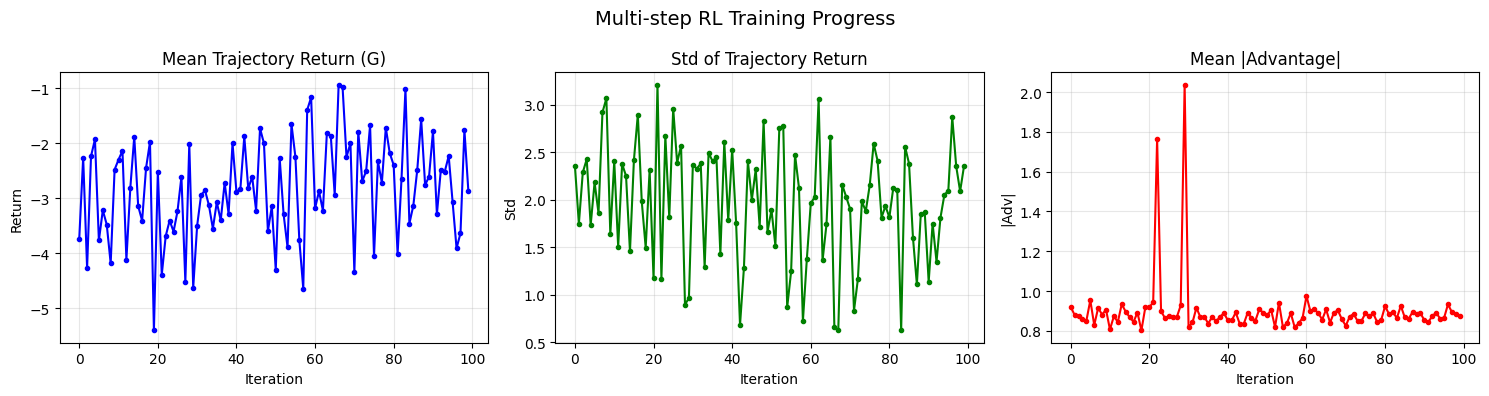

Saved reward decomposition plot to: output_subprocess/training_plots/reward_decomposition_subprocess_stage1_iters100_prompts4000_20260509_223406_580322.png


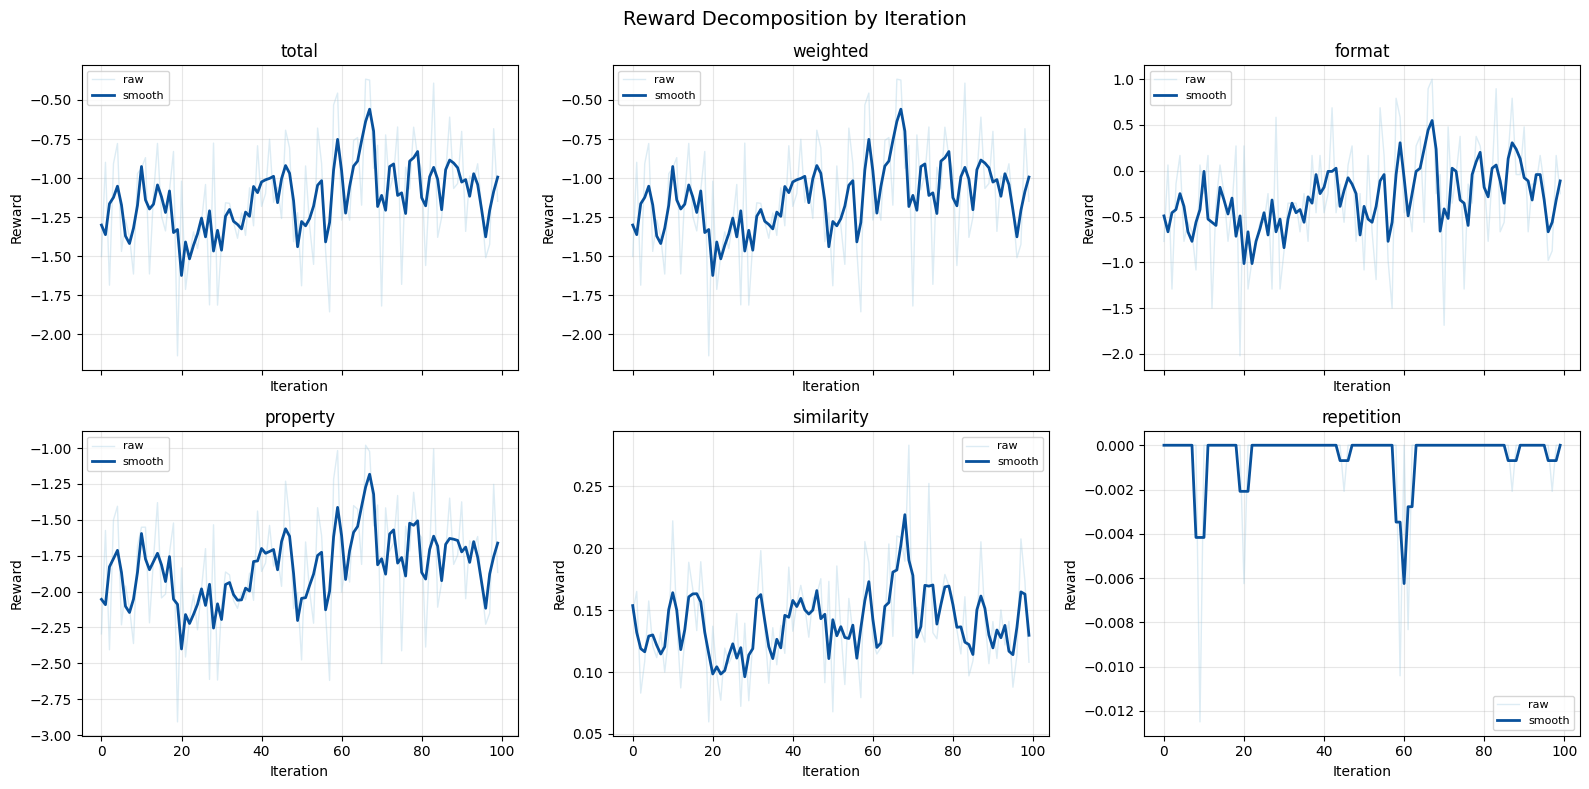

Saved subprocess metrics bundle to: out_subprocess/training_metrics/multiturn_subprocess_stage1_iters100_prompts4000_20260509_223406_580322


In [23]:
from datetime import datetime
from pathlib import Path
from matplotlib import pyplot as plt

if "all_metrics" not in globals():
    raise ValueError(
        "all_metrics is undefined. Run: all_metrics = run_multistep_rl_training_fixed(...) first."
    )
if not all_metrics:
    raise ValueError("all_metrics is empty. Please run training first.")

def _smooth_series(values, window: int = 3):
    """Simple moving average with edge padding for short metric series."""
    arr = np.asarray(values, dtype=np.float64)
    if arr.size == 0 or window <= 1 or arr.size < window:
        return arr.tolist()
    kernel = np.ones(window, dtype=np.float64) / window
    pad_left = window // 2
    pad_right = window - 1 - pad_left
    padded = np.pad(arr, (pad_left, pad_right), mode="edge")
    smooth = np.convolve(padded, kernel, mode="valid")
    return smooth.tolist()

iters = [m["iteration"] for m in all_metrics]
first = all_metrics[0]

SUBPROCESS_METRICS_OUTPUT_DIR = Path("out_subprocess/training_metrics")
SUBPROCESS_PLOTS_OUTPUT_DIR = Path("output_subprocess/training_plots")
SUBPROCESS_METRICS_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SUBPROCESS_PLOTS_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
save_dir = SUBPROCESS_PLOTS_OUTPUT_DIR

def _auto_run_tag() -> str:
    explicit = globals().get("RUN_TAG")
    if explicit:
        return str(explicit)
    parts = []
    experiment_name = globals().get("RUN_EXPERIMENT")
    if experiment_name:
        parts.append(str(experiment_name))
    parts.append(f"iters{len(all_metrics)}")
    if 'raw_data' in globals():
        parts.append(f"prompts{len(raw_data)}")
    parts.append(datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
    return "_".join(parts)

run_tag = _auto_run_tag()

def _assert_fresh_output_path(path: Path, *, kind: str) -> None:
    if path.exists():
        raise FileExistsError(
            f"Refusing to overwrite existing {kind}: {path}. Change run_tag before saving."
        )

if "mean_reward" in first:
    # Mode A metrics
    mean_reward = [m.get("mean_reward", 0.0) for m in all_metrics]
    mean_edit = [m.get("mean_edit", 0.0) for m in all_metrics]
    mean_outcome = [m.get("mean_outcome", 0.0) for m in all_metrics]

    axes[0].plot(iters, mean_reward, "b-o", markersize=3)
    axes[0].set_title("Mean Reward")
    axes[0].set_ylabel("Reward")

    axes[1].plot(iters, mean_edit, "g-o", markersize=3)
    axes[1].set_title("Mean EDIT Reward")
    axes[1].set_ylabel("Reward")

    axes[2].plot(iters, mean_outcome, "r-o", markersize=3)
    axes[2].set_title("Mean Outcome Reward")
    axes[2].set_ylabel("Reward")

    reward_component_keys = []

elif "mean_G" in first:
    # Mode B metrics
    mean_G = [m.get("mean_G", 0.0) for m in all_metrics]
    std_G = [m.get("std_G", 0.0) for m in all_metrics]

    # Under group-normalized GRPO, mean_adv is expected near 0.
    # Prefer |adv| and std_adv to observe signal strength.
    if "mean_abs_adv" in first:
        adv_signal = [m.get("mean_abs_adv", 0.0) for m in all_metrics]
        adv_title = "Mean |Advantage|"
        adv_ylabel = "|Adv|"
    else:
        adv_signal = [m.get("mean_adv", 0.0) for m in all_metrics]
        adv_title = "Mean Advantage"
        adv_ylabel = "Advantage"

    axes[0].plot(iters, mean_G, "b-o", markersize=3)
    axes[0].set_title("Mean Trajectory Return (G)")
    axes[0].set_ylabel("Return")

    axes[1].plot(iters, std_G, "g-o", markersize=3)
    axes[1].set_title("Std of Trajectory Return")
    axes[1].set_ylabel("Std")

    axes[2].plot(iters, adv_signal, "r-o", markersize=3)
    axes[2].set_title(adv_title)
    axes[2].set_ylabel(adv_ylabel)

    reward_component_keys = [
        ("mean_reward_total", "total"),
        ("mean_reward_weighted", "weighted"),
        ("mean_reward_format", "format"),
        ("mean_reward_property", "property"),
        ("mean_reward_similarity", "similarity"),
        ("mean_reward_repetition", "repetition"),
    ]

else:
    raise ValueError("Unknown metric schema in all_metrics.")

for ax in axes:
    ax.set_xlabel("Iteration")
    ax.grid(True, alpha=0.3)

plt.suptitle("Multi-step RL Training Progress", fontsize=14)
plt.tight_layout()
main_plot_path = save_dir / f"training_progress_{run_tag}.png"
_assert_fresh_output_path(main_plot_path, kind="training plot")
fig.savefig(main_plot_path, dpi=200, bbox_inches="tight")
print(f"Saved main training plot to: {main_plot_path}")
plt.show()

# Extra figure: reward decomposition curves for Mode B.
if reward_component_keys:
    fig2, axes2 = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
    axes2 = axes2.flatten()

    for ax, (metric_key, title) in zip(axes2, reward_component_keys):
        values = [m.get(metric_key, 0.0) for m in all_metrics]
        smooth_values = _smooth_series(values, window=3)
        ax.plot(iters, values, color="#9ecae1", linewidth=1.0, alpha=0.35, label="raw")
        ax.plot(iters, smooth_values, color="#08519c", linewidth=2.0, label="smooth")
        ax.set_title(title)
        ax.set_xlabel("Iteration")
        ax.set_ylabel("Reward")
        ax.grid(True, alpha=0.3)
        ax.legend(loc="best", fontsize=8)

    plt.suptitle("Reward Decomposition by Iteration", fontsize=14)
    plt.tight_layout()
    reward_plot_path = save_dir / f"reward_decomposition_{run_tag}.png"
    _assert_fresh_output_path(reward_plot_path, kind="reward decomposition plot")
    fig2.savefig(reward_plot_path, dpi=200, bbox_inches="tight")
    print(f"Saved reward decomposition plot to: {reward_plot_path}")
    plt.show()

import importlib
import training_metrics_io as _training_metrics_io

_training_metrics_io = importlib.reload(_training_metrics_io)

metrics_artifacts = _training_metrics_io.save_training_metrics_from_globals(
    globals(),
    output_dir=SUBPROCESS_METRICS_OUTPUT_DIR,
    run_name=f"multiturn_{run_tag}",
    allow_overwrite=False,
)
print(f"Saved subprocess metrics bundle to: {metrics_artifacts['run_dir']}")

## 9. Evaluate the Final Model

In [ ]:
SFT_CHECKPOINT_TO_EVAL = globals().get(
    "SFT_CHECKPOINT_TO_EVAL", globals().get("sft_checkpoint_path")
)
GRPO_CHECKPOINT_TO_EVAL = globals().get(
    "GRPO_CHECKPOINT_TO_EVAL", globals().get("grpo_checkpoint_path")
)

if not SFT_CHECKPOINT_TO_EVAL or not GRPO_CHECKPOINT_TO_EVAL:
    raise ValueError(
        "Set SFT_CHECKPOINT_TO_EVAL / GRPO_CHECKPOINT_TO_EVAL, or run the SFT and GRPO save cells first."
    )

sft_training_client = service_client.create_lora_training_client(
    base_model=BASE_MODEL,
    rank=LORA_RANK,
)
sft_training_client.load_state(SFT_CHECKPOINT_TO_EVAL)
sft_sampling_client = sft_training_client.save_weights_and_get_sampling_client(
    name="sft-sampler.eval"
)

grpo_training_client = service_client.create_lora_training_client(
    base_model=BASE_MODEL,
    rank=LORA_RANK,
)
grpo_training_client.load_state(GRPO_CHECKPOINT_TO_EVAL)
grpo_sampling_client = grpo_training_client.save_weights_and_get_sampling_client(
    name="grpo-sampler.eval"
)

print(f"Loaded SFT eval checkpoint: {SFT_CHECKPOINT_TO_EVAL}")
print(f"Loaded GRPO eval checkpoint: {GRPO_CHECKPOINT_TO_EVAL}")


## 10. Download the Trained Weights

You can download the LoRA adapter weights to use with your own inference setup (e.g., vLLM, SGLang, or HuggingFace).

In [27]:
# Download the GRPO model weights
# The downloaded weights are a LoRA adapter that can be loaded
# with HuggingFace PEFT or merged into the base model.

rest_client = service_client.create_rest_client()
rest_client.delete_checkpoint(checkpoint_id="weights/Stage1-subprocess-grpo.weekend.Qwen8B.0050",training_run_id="b07a8c9f-2d02-59d8-b4a7-6682b0369bee:train:6").result()  # Clean up any previous checkpoint to avoid confusion
# List available checkpoints
# future = rest_client.list_checkpoints("run_id").result()  # Uncomment to see all checkpoints
# Download to a local directory
# Uncomment and run when ready:
# rest_client.download_checkpoint(grpo_checkpoint_path, output_dir="./grpo-weights")
# print("Weights downloaded to ./grpo-weights/")

# print(f"GRPO checkpoint path: {grpo_checkpoint_path}")
# print("Uncomment the download line above when you're ready to export.")

---

## Summary & Next Steps

In this notebook, we:

1. **Loaded** the `Alan123/homo-lumo-grpo` dataset from HuggingFace
2. **SFT-trained** a Qwen3 model to learn the chemistry Q&A format using `cross_entropy` loss
3. **GRPO-trained** the model using RL with a custom reward function and `ppo` loss
4. **Compared** SFT vs GRPO predictions side by side

### Tips for better results:

- **More SFT steps** — if your dataset is large, train for more steps or multiple epochs
- **Tune the reward function** — the reward function is the most important part of GRPO. Make it reflect what you actually care about.
- **Try different loss functions** — Tinker supports `importance_sampling`, `ppo`, `cispo`, and `dro`. See the [Loss Functions docs](https://tinker-docs.thinkingmachines.ai/losses)
- **Increase samples per prompt** — more completions per prompt = better advantage estimates
- **Use a larger model** — `Qwen/Qwen3-30B-A3B` (MoE) is very cost-effective and much more capable
- **Use the Tinker Cookbook** — the cookbook has optimized training loops with async operations, logging, and eval. See [rl/train.py](https://github.com/thinking-machines-lab/tinker-cookbook/blob/main/tinker_cookbook/rl/train.py)

### Key Tinker resources:
- [Tinker API Docs](https://tinker-docs.thinkingmachines.ai/)
- [Supervised Learning Guide](https://tinker-docs.thinkingmachines.ai/supervised-learning/sl-basic)
- [RL Training Guide](https://tinker-docs.thinkingmachines.ai/rl/rl-basic)
- [Model Lineup](https://tinker-docs.thinkingmachines.ai/model-lineup)
- [Tinker Cookbook (GitHub)](https://github.com/thinking-machines-lab/tinker-cookbook)

In [40]:
# Diagnose one subprocess prompt turn by turn.
# This cell prints the exact user context sent to the model, the model output,
# reward decomposition, external VERIFY, and the next-turn context.

from datetime import datetime

DIAG_PROMPT_IDX = 0
DIAG_MAX_TURNS = 3
DIAG_TEMPERATURE = 0.3
DIAG_MAX_TOKENS = 384
DIAG_SAMPLING_SOURCE = "sft"  # "sft" | "grpo" | "base"

def _make_diagnostic_sampling_client():
    """Create a SamplingClient; TrainingClient itself has no sample()."""
    source = str(DIAG_SAMPLING_SOURCE).lower()
    if source == "sft":
        if "sft_sampling_client" in globals():
            print("Using existing SFT sampling client for diagnostics.")
            return sft_sampling_client
        checkpoint = globals().get("SFT_CHECKPOINT_FOR_GRPO") or globals().get("sft_checkpoint_path")
        if checkpoint:
            print(f"Loading SFT checkpoint for diagnostic sampling: {checkpoint}")
            client = service_client.create_lora_training_client(base_model=BASE_MODEL, rank=LORA_RANK)
            client.load_state(checkpoint)
            return client.save_weights_and_get_sampling_client(
                name=f"subprocess-sft-diagnostic-{datetime.now().strftime('%Y%m%d-%H%M%S')}"
            )
        print("No SFT sampling client/checkpoint found; falling back to base model.")
        source = "base"
    if source == "grpo" and "grpo_training_client" in globals():
        try:
            name = f"subprocess-grpo-diagnostic-{datetime.now().strftime('%Y%m%d-%H%M%S')}"
            print(f"Saving current training weights for diagnostic sampling: {name}")
            return grpo_training_client.save_weights_and_get_sampling_client(name=name)
        except Exception as exc:
            print(f"Could not create diagnostic client from training weights: {exc}")
            print("Falling back to base-model sampling client.")
    print("Using base-model sampling client for diagnostics.")
    return service_client.create_sampling_client(base_model=BASE_MODEL)

diag_sampling_client = _make_diagnostic_sampling_client()

example = raw_data[int(DIAG_PROMPT_IDX)]
ground_truth = str(example[ANSWER_COL])
current_prompt_for_generation = _with_external_context(
    build_two_step_user_prompt(example, include_analysis=False)
)

print("=" * 100)
print(f"Diagnostic renderer={globals().get('RENDERER_NAME', type(renderer).__name__)}")
print(f"Diagnostic sampling source={DIAG_SAMPLING_SOURCE}")
if globals().get("RENDERER_NAME") != "qwen3_disable_thinking":
    print("WARNING: subprocess diagnostics should use qwen3_disable_thinking to avoid <think> outputs.")
print(f"Subprocess diagnostic prompt idx={DIAG_PROMPT_IDX}")
print("Ground truth EDIT / target answer:")
print(ground_truth)
print("=" * 100)


for turn_idx in range(DIAG_MAX_TURNS):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT_RL},
        {"role": "user", "content": current_prompt_for_generation},
    ]

    print(f"\n{'=' * 36} TURN {turn_idx} INPUT {'=' * 36}")
    print("[SYSTEM]")
    print(SYSTEM_PROMPT_RL.strip())
    print("\n[USER]")
    print(current_prompt_for_generation)

    prompt_input = renderer.build_generation_prompt(messages)
    result = diag_sampling_client.sample(
        prompt=prompt_input,
        sampling_params=types.SamplingParams(
            max_tokens=DIAG_MAX_TOKENS,
            temperature=DIAG_TEMPERATURE,
            stop=renderer.get_stop_sequences(),
        ),
        num_samples=1,
    ).result()

    seq = result.sequences[0]
    completion_text = tokenizer.decode(seq.tokens, skip_special_tokens=True)
    completion_text = _normalize_completion_text(completion_text)

    print(f"\n{'=' * 35} TURN {turn_idx} OUTPUT {'=' * 35}")
    print(completion_text)

    reward_components = compute_reward_components(
        completion_text,
        current_prompt_for_generation,
        ground_truth,
        reward_weights=resolve_reward_weights(False),
    )
    print(f"\n{'=' * 34} TURN {turn_idx} REWARD {'=' * 34}")
    for key in [
        "total",
        "weighted_total",
        "strict",
        "property",
        "similarity",
        "repetition",
        "has_plan_block",
        "has_edit_block",
        "contains_forbidden_analyse_or_verify",
        "has_smiles",
        "valid_smiles",
    ]:
        print(f"{key}: {reward_components.get(key)}")

    env_feedback, mol_out, all_met = _run_env(completion_text, current_prompt_for_generation)
    verify_block = _build_verify_block(
        completion_text,
        env_feedback,
        mol_out,
        all_met,
        current_prompt_for_generation,
    )

    print(f"\n{'=' * 34} TURN {turn_idx} VERIFY {'=' * 34}")
    print(verify_block)

    pred_smiles = extract_smiles(_extract_edit_text(completion_text))
    if pred_smiles and mol_out is not None:
        # Reuse the same update logic as run_mode_b: current molecule, refreshed target gaps,
        # and current ANALYSE are moved into the next prompt. VERIFY stays in logs only.
        def _diag_replace_prompt_smiles(base_prompt: str, current_smiles: str) -> str:
            core_prompt = _strip_external_context_blocks(base_prompt)
            new_prompt = re.sub(
                r"<SMILES>.*?</SMILES>",
                lambda _m: f"<SMILES>{current_smiles}</SMILES>",
                core_prompt,
                count=1,
                flags=re.DOTALL,
            )

            fragments = _fragment_list_for_analysis(current_smiles)
            new_prompt = re.sub(
                r"(<SMILES>.*?</SMILES>)(?:,\s*which is composed of fragments\s+.*?\.)?",
                lambda m: f"{m.group(1)}, which is composed of fragments {repr(fragments)}.",
                new_prompt,
                count=1,
                flags=re.DOTALL,
            )

            mol_old = _mol_from_prompt(core_prompt)
            mol_new = Chem.MolFromSmiles(current_smiles)
            if mol_old is None or mol_new is None:
                return _with_external_context(new_prompt)

            for prop, fn, is_qed in [
                ("QED", QED.qed, True),
                ("LogP", Crippen.MolLogP, False),
                ("MW", Descriptors.ExactMolWt, False),
            ]:
                m = re.search(rf"<{prop}>(-?\d*\.?\d+)</{prop}>\s*(higher|lower)", new_prompt)
                if not m:
                    continue
                old_delta = float(m.group(1))
                old_dir = m.group(2).lower()
                old_base = float(fn(mol_old))
                target_abs = old_base + (old_delta if old_dir == "higher" else -old_delta)
                if is_qed:
                    target_abs = max(0.01, min(0.99, target_abs))
                new_base = float(fn(mol_new))
                new_dir = "higher" if target_abs >= new_base else "lower"
                new_delta = abs(target_abs - new_base)
                new_prompt = re.sub(
                    rf"<{prop}>-?\d*\.?\d+</{prop}>\s*(higher|lower)",
                    f"<{prop}>{new_delta:.3f}</{prop}> {new_dir}",
                    new_prompt,
                    count=1,
                )
            return _with_external_context(new_prompt)

        current_prompt_for_generation = _diag_replace_prompt_smiles(
            current_prompt_for_generation,
            pred_smiles,
        )
    else:
        current_prompt_for_generation = _with_external_context(current_prompt_for_generation)

    print(f"\n{'=' * 31} NEXT TURN CONTEXT PREVIEW {'=' * 31}")
    print(current_prompt_for_generation)

    if all_met:
        print("\nAll targets met. Stopping diagnostic early.")
        break


Using existing SFT sampling client for diagnostics.
Diagnostic renderer=qwen3
Diagnostic sampling source=sft
Subprocess diagnostic prompt idx=0
Ground truth EDIT / target answer:
Replace c1cn(C)c2c(Cl)ncnc12 with c1nnc(N/N=C\c2cccc(C)c2)nc1[O-] to form <SMILES>Cc1cccc(/C=N\Nc2nnc(-c3ccccc3)c([O-])n2)c1</SMILES>.

==================================== TURN 0 INPUT ====================================
[SYSTEM]
You are a chemistry assistant for multi-turn molecule optimization.

You must follow the output format exactly.

Critical output rules:
1) Your response must start immediately with <PLAN>.
2) Do not output <think>, </think>, hidden reasoning tags, markdown, code fences,
   explanations, greetings, or any text before <PLAN>.
3) Output exactly two XML blocks, in this exact order:
   <PLAN> ... </PLAN>
   <EDIT> ... </EDIT>
4) Do not output any other XML blocks, including <ANALYSE>, <VERIFY>, <ANSWER>,
   <FINAL>, or <REASONING>.

PLAN rules:
5) <PLAN> must contain 2-4 concise sentence